# ЛР 1–4. Анализ данных, предобработка, детекция выбросов и генерация признаков

**Датасет:** Dota 2 — определение локации концентрации энергии Древних  
**Подгруппа:** МО-241

Ноутбук объединяет четыре лабораторные работы и построен линейно:

1. данные изучаются «как есть» — до разделения на выборки;
2. выборка делится на train и test;
3. **все параметры преобразований оцениваются только на train**, а к test применяются уже обученные правила;
4. выбросы и аномалии ищутся уже в подготовленных признаках, поэтому их поиск не искажает импутацию и кодирование;
5. новые признаки генерируются детерминированными формулами, а масштабирование и baseline-модели обучаются после отбора признаков.

## Содержание

**ЛР 1. Формализация задачи и первичный анализ данных**

1. [Постановка задачи и предметная область](#sec1)
2. [Описание признаков и целевой переменной](#sec2)
3. [Фиксация виртуального окружения](#sec3)
4. [Загрузка данных и первичный осмотр](#sec4)
5. [Анализ природы признаков](#sec5)
6. [Диагностика пропусков](#sec6)
7. [Детерминированные преобразования до сплита](#sec7)
8. [Разделение на train и test](#sec8)

**ЛР 2. Заполнение пропусков и кодирование категориальных признаков**

9. [Агрегация редких классов](#sec9)
10. [Статистические методы заполнения пропусков](#sec10)
11. [Машинные методы заполнения пропусков](#sec11)
12. [Выбор метода и финальное заполнение](#sec12)
13. [Кодирование категориальных признаков](#sec13)
14. [Выводы по ЛР 1 и ЛР 2](#sec14)

**ЛР 3. Детекция выбросов и аномалий**

15. [Детекция выбросов и аномалий](#sec15)
    - [Постановка и данные](#sec15-1)
    - [Гистограммы и ящики с усами](#sec15-2)
    - [Выбор метода поиска выбросов](#sec15-3)
    - [Границы выбросов на гистограммах](#sec15-4)
    - [Результаты поиска выбросов по столбцам](#sec15-5)
    - [Многомерная детекция аномалий](#sec15-6)
    - [Сравнение решений алгоритмов](#sec15-7)
    - [Визуализация аномалий через PCA](#sec15-8)
    - [Решение об удалении объектов](#sec15-9)
    - [Итоговое состояние данных и выводы по ЛР 3](#sec15-10)

**ЛР 4. Генерация новых признаков, скалирование и baseline**

16. [Генерация признаков, масштабирование и baseline](#sec16)
    - [Задача ЛР 4 и исходные данные](#sec16-1)
    - [Какие признаки генерировать](#sec16-2)
    - [Проверка новых признаков](#sec16-3)
    - [Диагностика диспропорции](#sec16-4)
    - [Сравнение вариантов масштабирования](#sec16-5)
    - [Проверка пользы признаков и отбор](#sec16-6)
    - [Финальное масштабирование и baseline](#sec16-7)
    - [Проверки корректности и итоговые данные](#sec16-8)

<a id='sec1'></a>
## 1. Постановка задачи и предметная область

### Бизнес-контекст

В обычные материалы проникают микроскопические осколки Radiant и Dire. Осколки распределяются
в веществе неравномерно: в одних образцах энергия уходит вглубь, в других остаётся у поверхности,
в третьих образует устойчивый промежуточный слой.

Маги уже собрали характеристики образцов: отклик на энергию Radiant и Dire, наличие магических
меток, заряд эссенции, состав внутренней энергии и характер её распространения по внешним
и внутренним слоям. Не хватает последнего шага — связать эти характеристики с расположением энергии.

### Потребность заказчика

| Что нужно заказчику | Как это отражено в задаче |
|---|---|
| Находить следы Древних раньше, чем влияние станет заметным | модель работает только по измеренным характеристикам образца |
| Знать, **где** энергия, а не только сколько её | целевая переменная — категория локации, а не число |
| Работать с одним образцом | выход модели — одна метка класса для одного объекта |

### Формализация ML-задачи

| Параметр | Значение |
|---|---|
| Тип задачи | многоклассовая классификация |
| Объект | один образец вещества с набором измеренных характеристик |
| Входные признаки | 7 характеристик образца |
| Целевой признак | `class` — локация концентрации осколков |
| Выход модели | метка класса локации для нового образца |
| Основная метрика (в следующих ЛР) | macro F1, так как классы сильно несбалансированы |

### План работы

**ЛР 1.** Изучить данные, понять природу признаков и пропусков, зафиксировать окружение,
выполнить детерминированные преобразования и разделить выборку на train и test.

**ЛР 2.** На train сравнить статистические и машинные методы заполнения пропусков, выбрать
лучший, применить его к test и закодировать категориальные признаки.

<a id='sec2'></a>
## 2. Описание признаков и целевой переменной

| Признак | Семантика | Тип | Роль |
|---|---|---|---|
| `radiant_resonance` | отклик вещества на энергию Radiant | вещественный | входной |
| `dire_resonance` | отклик вещества на энергию Dire | вещественный | входной |
| `arcane_mark` | наличие особой магической метки | категориальный, 2 уровня | входной |
| `energy_charge` | заряд эссенции | категориальный, 2 уровня | входной |
| `essence_composition` | состав внутренней энергии | вещественный | входной |
| `outer_energy_flow` | характер распространения по внешним слоям | вещественный | входной |
| `inner_energy_flow` | характер распространения по внутренним слоям | вещественный | входной |
| `class` | локация концентрации осколков | категориальный, 8 уровней | целевой |

В выборке 336 наблюдений и 8 столбцов, пропусков в целевой переменной нет.

### Классы целевого признака

| Класс | Объектов | Доля |
|---|---|---|
| `inner_core` | 143 | 42.56% |
| `inner_barrier` | 77 | 22.92% |
| `inner_layer` | 52 | 15.48% |
| `deep_barrier` | 35 | 10.42% |
| `outer_layer` | 20 | 5.95% |
| `outer_crust` | 5 | 1.49% |
| `penetration_layer` | 2 | 0.60% |
| `inner_crust` | 2 | 0.60% |

Доминирует `inner_core`, а три последних класса дают 9 объектов суммарно (2.7%). Такой дисбаланс
ограничивает обучение, поэтому решение по редким классам принимается отдельно в разделе 9.

<a id='sec3'></a>
## 3. Фиксация виртуального окружения

Работа выполнена на Python 3.13. Версии библиотек:

| Библиотека | Версия | Назначение |
|---|---|---|
| pandas | 3.0.2 | загрузка и обработка таблиц |
| numpy | 2.4.4 | численные вычисления |
| scikit-learn | 1.8.0 | сплит, импутация, кодирование, метрики |
| matplotlib | 3.11.2 | визуализация |
| seaborn | 0.13.2 | статистическая визуализация |
| missingno | 0.5.2 | визуализация пропусков |

Для воспроизводимости фиксируется `SEED = 5`: он передаётся в `train_test_split`,
в кросс-валидацию и в `IterativeImputer`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    cross_validate,
    StratifiedKFold,
    RepeatedStratifiedKFold,
)
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import silhouette_score, f1_score, accuracy_score
from sklearn.utils.multiclass import type_of_target
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.covariance import EllipticEnvelope
from sklearn.decomposition import PCA

In [2]:
import itertools
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)

SEED = 5
np.random.seed(SEED)

<a id='sec4'></a>
## 4. Загрузка данных и первичный осмотр

Данные лежат в CSV с разделителем `;` и десятичной точкой. Читаем файл и проверяем,
что таблица загрузилась корректно.

In [3]:
PATH = 'dota.csv'

df = pd.read_csv(PATH, sep=';', decimal='.')
df.head()

,radiant_resonance,dire_resonance,arcane_mark,energy_charge,essence_composition,outer_energy_flow,inner_energy_flow,class
0,0.49,0.29,NaN,0.5,0.56,0.24,0.35,inner_core
1,0.07,0.40,0.48,0.5,0.54,0.35,0.44,inner_core
2,0.56,0.40,0.48,0.5,0.49,0.37,0.46,inner_core
3,0.59,0.49,0.48,0.5,0.52,0.45,0.36,inner_core
4,NaN,NaN,0.48,0.5,0.55,0.25,0.35,inner_core


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 336 entries, 0 to 335
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   radiant_resonance    248 non-null    float64
 1   dire_resonance       289 non-null    float64
 2   arcane_mark          312 non-null    float64
 3   energy_charge        316 non-null    float64
 4   essence_composition  336 non-null    float64
 5   outer_energy_flow    336 non-null    float64
 6   inner_energy_flow    336 non-null    float64
 7   class                336 non-null    str    
dtypes: float64(7), str(1)
memory usage: 21.1 KB


In [5]:
print('Размер таблицы:', df.shape)
print('Полных дубликатов:', df.duplicated().sum())
print()
print('Пропуски по столбцам:')
print(df.isna().sum())

Размер таблицы: (336, 8)
Полных дубликатов: 0

Пропуски по столбцам:
radiant_resonance      88
dire_resonance         47
arcane_mark            24
energy_charge          20
essence_composition     0
outer_energy_flow       0
inner_energy_flow       0
class                   0
dtype: int64


### 4.1. Выводы по загрузке

- Таблица прочитана корректно: 336 строк, 8 столбцов, целевой признак заполнен полностью.
- Полных дубликатов нет.
- Пропуски есть только в четырёх входных признаках: `radiant_resonance` (88),
  `dire_resonance` (47), `arcane_mark` (24), `energy_charge` (20). В остальных признаках
  и в `class` пропусков нет.
- Все 7 входных признаков загрузились как `float64`, включая `arcane_mark` и `energy_charge`,
  которые по семантике являются категориальными. Это нужно исправить до подачи данных в модель.

<a id='sec5'></a>
## 5. Анализ природы признаков

Тип, записанный в CSV, ещё не описывает природу признака. Посмотрим число уникальных значений
и распределение, чтобы отделить вещественные измерения от категориальных флагов.

In [6]:
features = [c for c in df.columns if c != 'class']

summary = pd.DataFrame({
    'уникальных': df[features].nunique(),
    'пропусков': df[features].isna().sum(),
    'минимум': df[features].min(),
    'медиана': df[features].median(),
    'максимум': df[features].max(),
})
summary.round(3)

,уникальных,пропусков,минимум,медиана,максимум
radiant_resonance,76,88,0.00,0.500,0.89
dire_resonance,63,47,0.16,0.470,1.00
arcane_mark,2,24,0.48,0.480,1.00
energy_charge,2,20,0.50,0.500,1.00
essence_composition,59,0,0.00,0.495,0.88
outer_energy_flow,82,0,0.03,0.455,1.00
inner_energy_flow,77,0,0.00,0.430,0.99


In [7]:
for col in ['arcane_mark', 'energy_charge']:
    print(col)
    print(df[col].value_counts(dropna=False))
    print()

arcane_mark
arcane_mark
0.48    303
NaN      24
1.00      9
Name: count, dtype: int64

energy_charge
energy_charge
0.5    315
NaN     20
1.0      1
Name: count, dtype: int64



In [8]:
df[features].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
radiant_resonance,248.0,0.497,0.197,0.00,0.34,0.500,0.663,0.89
dire_resonance,289.0,0.503,0.153,0.16,0.40,0.470,0.570,1.00
arcane_mark,312.0,0.495,0.087,0.48,0.48,0.480,0.480,1.00
energy_charge,316.0,0.502,0.028,0.50,0.50,0.500,0.500,1.00
essence_composition,336.0,0.500,0.122,0.00,0.42,0.495,0.570,0.88
outer_energy_flow,336.0,0.500,0.216,0.03,0.33,0.455,0.710,1.00
inner_energy_flow,336.0,0.500,0.209,0.00,0.35,0.430,0.710,0.99


### 5.1. Две группы признаков

**Вещественные признаки:** `radiant_resonance`, `dire_resonance`, `essence_composition`,
`outer_energy_flow`, `inner_energy_flow`. У них 59–82 уникальных значения и непрерывное
распределение — это измеренные величины.

**Категориальные признаки:** `arcane_mark` и `energy_charge`. Формально они записаны как
`float64`, но фактически имеют два уровня:

- `arcane_mark`: `0.48` — 303 объекта, `1.00` — 9 объектов, пропуск — 24;
- `energy_charge`: `0.50` — 315 объектов, `1.00` — 1 объект, пропуск — 20.

Значения `0.48` и `0.50` — базовый уровень «событие не зафиксировано», а `1.00` — редкое
событие. Между `0.50` и `1.00` нет градации, поэтому подавать такие столбцы как непрерывные
числа нельзя.

Уровень `1.00` в `energy_charge` представлен одним наблюдением: признак практически вырожден,
и его судьба решается отдельно после сплита по статистике train.

Пропуск в этих столбцах по смыслу означает то же, что и базовый уровень: «событие не
зафиксировано». Это позволяет закрыть пропуски детерминированным правилом до сплита, не заглядывая
в test.

<a id='sec6'></a>
## 6. Диагностика пропусков

Перед выбором метода заполнения нужно понять структуру потерь: сосредоточены ли пропуски
в одних и тех же строках, связаны ли столбцы между собой и связаны ли пропуски с классом.

In [9]:
miss_cols = ['radiant_resonance', 'dire_resonance', 'arcane_mark', 'energy_charge']

row_missing = df[miss_cols].isna().sum(axis=1)
pd.crosstab(row_missing, df['class'], margins=True)

class,deep_barrier,inner_barrier,inner_core,inner_crust,inner_layer,outer_crust,outer_layer,penetration_layer,All
row_0,,,,,,,,,
0,22,39,82,2,27,3,12,1,188
1,10,32,50,0,19,1,7,1,120
2,2,6,10,0,5,1,1,0,25
3,1,0,1,0,1,0,0,0,3
All,35,77,143,2,52,5,20,2,336


In [10]:
df[miss_cols].isna().astype(int).corr().round(3)

,radiant_resonance,dire_resonance,arcane_mark,energy_charge
radiant_resonance,1.000,0.053,-0.034,-0.035
dire_resonance,0.053,1.000,0.021,-0.065
arcane_mark,-0.034,0.021,1.000,0.174
energy_charge,-0.035,-0.065,0.174,1.000


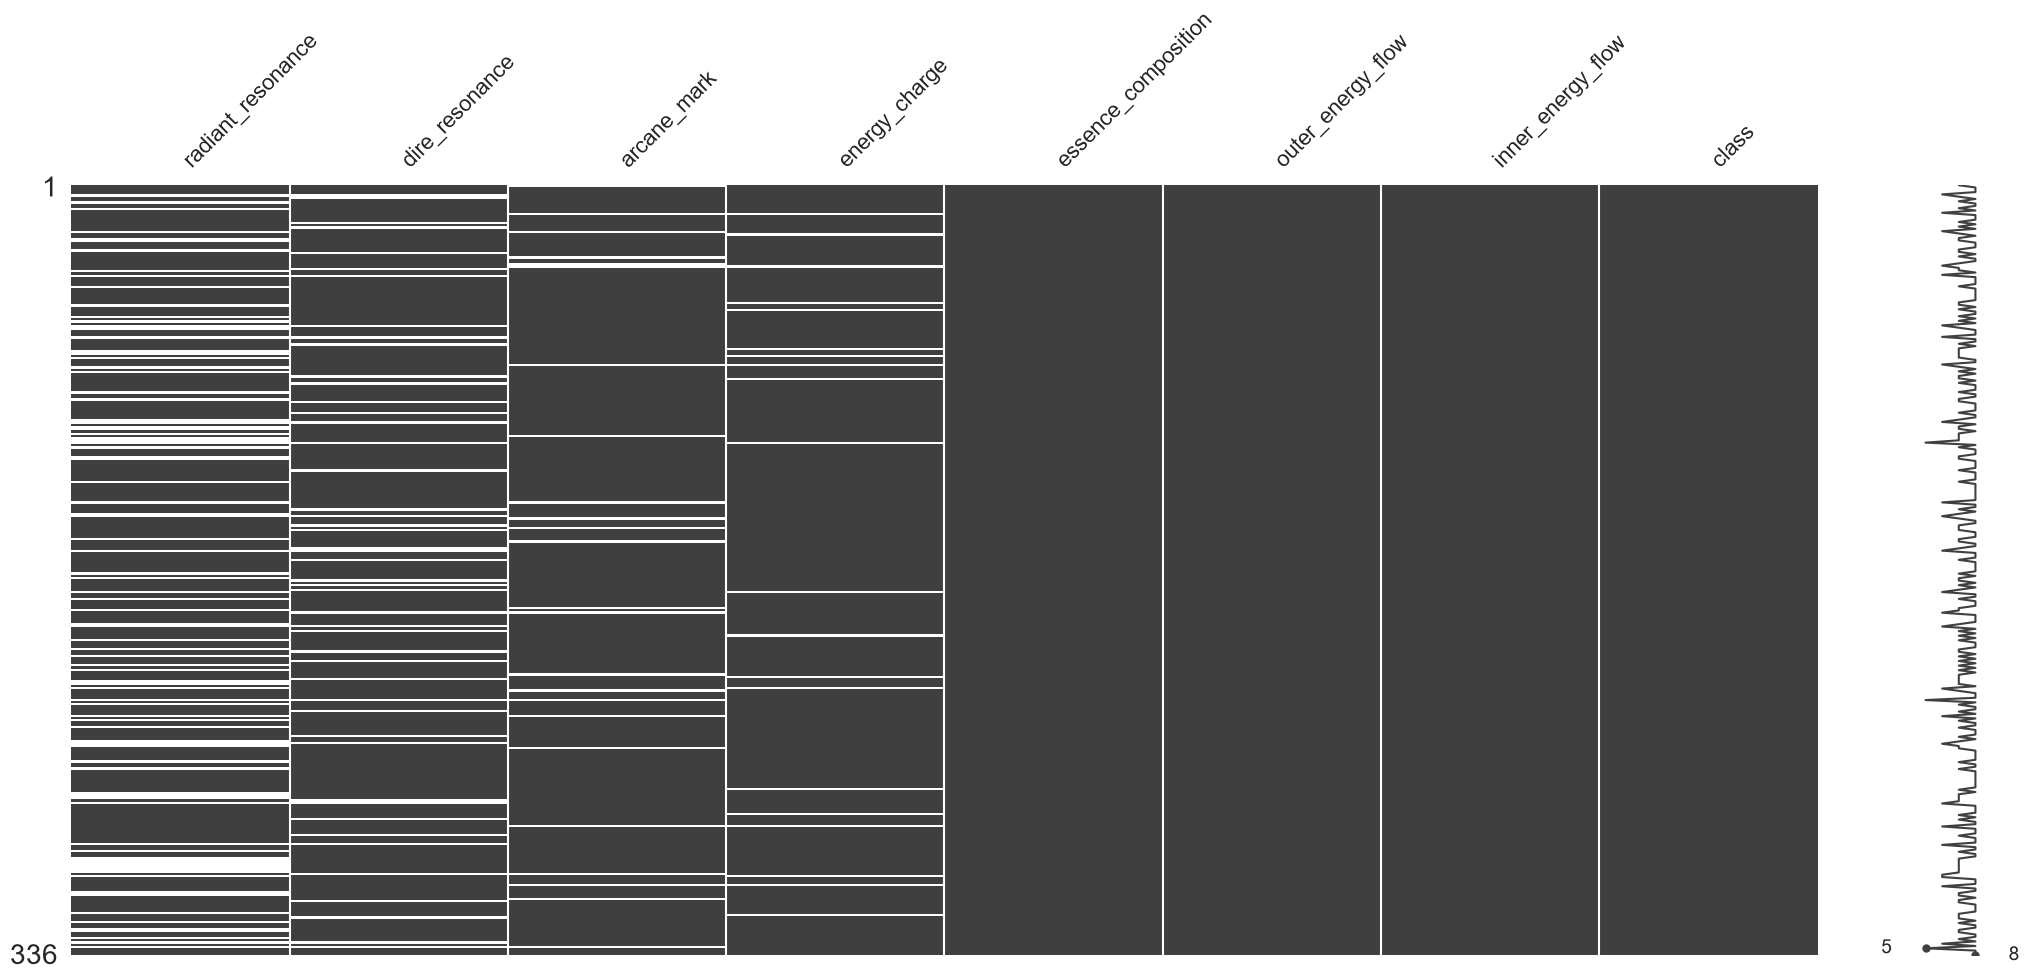

In [11]:
msno.matrix(df)
plt.show()

In [12]:
miss_by_class = (df[miss_cols].isna().groupby(df['class']).mean() * 100).round(1)
miss_by_class.loc['ВСЕ КЛАССЫ'] = (df[miss_cols].isna().mean() * 100).round(1)
miss_by_class

,radiant_resonance,dire_resonance,arcane_mark,energy_charge
class,,,,
deep_barrier,28.6,11.4,8.6,0.0
inner_barrier,24.7,19.5,7.8,5.2
inner_core,25.2,12.6,6.3,7.0
inner_crust,0.0,0.0,0.0,0.0
inner_layer,36.5,11.5,7.7,5.8
outer_crust,0.0,20.0,20.0,20.0
outer_layer,20.0,15.0,0.0,10.0
penetration_layer,0.0,0.0,50.0,0.0
ВСЕ КЛАССЫ,26.2,14.0,7.1,6.0


### 6.1. Выводы по структуре пропусков

**По строкам.** У большинства объектов либо нет пропусков, либо он один. Строк, где потеряно
сразу несколько значений, очень мало. Удалять наблюдения по числу пропусков невыгодно:
вместе с пропуском ушло бы всё остальное содержание объекта.

**По связям между столбцами.** Корреляции индикаторов пропуска слабые. Заметна только связь
`arcane_mark` — `energy_charge`, что объясняется общей природой этих двух индикаторов.

**По связи с классом.** В надёжных по объёму классах (`inner_core` 143, `inner_barrier` 77,
`inner_layer` 52, `deep_barrier` 35) доля пропусков близка к общей. Отклонения не превышают
одной-двух стандартных ошибок доли, то есть статистически незначимы. В классах по 2–5 объектов
доли меняются на десятки процентов от одного наблюдения — это шум малых групп.

**Вывод.** Пропуски не блочные и систематически с классом не связаны, картина близка к MCAR.
Отсюда три решения:

1. строки с пропусками не удаляются, выполняется заполнение;
2. индикаторы пропуска как отдельные признаки не вводятся: сам факт потери не несёт сигнала;
3. пропуски в `arcane_mark` и `energy_charge` закрываются детерминированным правилом
   в разделе 7, а методы заполнения сравниваются на вещественных резонансах.

<a id='sec7'></a>
## 7. Детерминированные преобразования до сплита

Часть преобразований не требует оценки параметров по данным: это правила, заданные семантикой
признака. Их можно применять до разделения выборки, потому что они не переносят информацию
из test в train.

### 7.1. Признак `arcane_mark`

Признак имеет два уровня: `0.48` — метка не зафиксирована, `1.00` — метка есть. Перекодируем
его в бинарный флаг: `1.00` становится `1`, остальные значения и пропуск — `0`. Пропуск
получает `0` осознанно: «записи о метке нет» и «метки нет» в этой задаче не различаются.

Правило `value == 1.00` не содержит оцениваемого параметра и не опирается на статистику выборки,
поэтому утечки не создаёт. После перекодирования пропуски в столбце закрыты.

In [13]:
df['arcane_mark'] = (df['arcane_mark'] == 1.00).astype('int8')

print(df['arcane_mark'].value_counts())
print('Пропусков:', df['arcane_mark'].isna().sum())

arcane_mark
0    327
1      9
Name: count, dtype: int64
Пропусков: 0


Судьба признака `energy_charge` здесь **не** решается: его вырожденность подтверждается
счётчиками на train, поэтому решение переносится в раздел 13, где кодируются категориальные
признаки.

<a id='sec8'></a>
## 8. Разделение на train и test

### 8.1. Параметры сплита

| Параметр | Значение | Обоснование |
|---|---|---|
| `test_size` | 0.30 | при 0.20 классы по 2 объекта не попадают в test; 0.30 гарантирует все классы в обеих частях |
| `stratify` | `class` | сохраняет пропорции классов при сильном дисбалансе |
| `shuffle` | `True` | временного порядка в данных нет, перемешивание убирает артефакты порядка записи |
| `random_state` | `SEED = 5` | воспроизводимость |

Сплит выполняется **до** любых оценок по данным: агрегации классов, сравнения импутеров,
обучения кодировщиков.

In [14]:
TEST_SIZE = 0.30

train_df, test_df = train_test_split(
    df,
    test_size=TEST_SIZE,
    stratify=df['class'],
    random_state=SEED,
    shuffle=True,
)

X_train = train_df.drop(columns=['class']).copy()
X_test = test_df.drop(columns=['class']).copy()
y_train = train_df['class'].copy()
y_test = test_df['class'].copy()

print('X_train:', X_train.shape)
print('X_test: ', X_test.shape)

X_train: (235, 7)
X_test:  (101, 7)


In [15]:
split_check = pd.DataFrame({
    'train': y_train.value_counts(),
    'test': y_test.value_counts(),
}).fillna(0).astype(int)
split_check['доля в train, %'] = (split_check['train'] / len(y_train) * 100).round(1)
split_check

,train,test,"доля в train, %"
class,,,
deep_barrier,25,10,10.6
inner_barrier,54,23,23.0
inner_core,100,43,42.6
inner_crust,1,1,0.4
inner_layer,36,16,15.3
outer_crust,4,1,1.7
outer_layer,14,6,6.0
penetration_layer,1,1,0.4


### 8.2. Вывод по сплиту

В train 235 объектов, в test 101. Все восемь классов присутствуют в обеих частях, пропорции
сохранены стратификацией.

Дальше действует правило: **train — единственный источник оценок**, test только преобразуется
обученными на train правилами.

| Преобразование | Настраивается | Применяется |
|---|---|---|
| Заполнение пропусков | train | train и test |
| Агрегация редких классов | train, по счётчикам | train и test |
| Кодирование категориальных признаков | train | train и test |

<a id='sec9'></a>
## 9. Агрегация редких классов

### 9.1. Постановка проблемы

Смотрим на счётчики классов **в train**:

| Класс | train | test |
|---|---|---|
| `outer_crust` | 4 | 1 |
| `inner_crust` | 1 | 1 |
| `penetration_layer` | 1 | 1 |

Класс из одного объекта нельзя ни обучить, ни проверить: метрика по нему определяется одним
наблюдением. Такие классы нужно укрупнить.

### 9.2. Две конкурирующие схемы

| Схема | Что делаем | Ожидаемый эффект |
|---|---|---|
| `rare_other` | три класса с числом объектов < 10 объединяем в `rare_other` | каждый класс становится обучаемым |
| `layer` | объединяем `outer_layer` и `inner_layer` в один слой | уменьшаем число классов, но редкие классы остаются |

Вторая схема — гипотеза: `outer_layer` и `inner_layer` похожи по смыслу (оба про слой),
поэтому, возможно, их стоит объединить. Проверим это тремя аргументами.

In [16]:
RARE_THRESHOLD = 10

train_counts = y_train.value_counts()
rare_classes = train_counts[train_counts < RARE_THRESHOLD].index.tolist()

print('Редкие классы в train:', rare_classes)
print(train_counts[rare_classes])

Редкие классы в train: ['outer_crust', 'inner_crust', 'penetration_layer']
class
outer_crust          4
inner_crust          1
penetration_layer    1
Name: count, dtype: int64


**Аргумент 1: средние и медианные значения признаков.** Если классы близки по признакам,
объединение не теряет информации.

In [17]:
num_cols = [
    'radiant_resonance',
    'dire_resonance',
    'essence_composition',
    'outer_energy_flow',
    'inner_energy_flow',
]

layer_pair = X_train[y_train.isin(['outer_layer', 'inner_layer'])].copy()
layer_pair['class'] = y_train[y_train.isin(['outer_layer', 'inner_layer'])]

layer_pair.groupby('class')[num_cols].agg(['mean', 'median']).round(3)

radiant_resonance        dire_resonance        essence_composition        outer_energy_flow        inner_energy_flow       
                         mean median           mean median                mean median              mean median              mean median
class                                                                                                                                  
inner_layer             0.677   0.68          0.718  0.720               0.432  0.450             0.460  0.445             0.349   0.35
outer_layer             0.670   0.66          0.734  0.755               0.723  0.735             0.479  0.515             0.303   0.29

**Аргумент 2: разделимость классов.** Обучим логистическую регрессию различать только эти два
класса с кросс-валидацией на train. Если классы однородны, точность будет близка к случайному
уровню 0.5.

In [18]:
layer_clf = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler(),
    LogisticRegression(max_iter=2000),
)

layer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

layer_scores = cross_val_score(
    layer_clf,
    layer_pair[num_cols],
    layer_pair['class'],
    cv=layer_cv,
    scoring='accuracy',
)

print('Точность по фолдам:', layer_scores.round(3))
print('Средняя точность:', round(layer_scores.mean(), 3))

Точность по фолдам: [0.9 1.  1.  0.9 0.9]
Средняя точность: 0.94


**Аргумент 3: структура данных.** Сравним silhouette на train для четырёх вариантов разметки.
Silhouette считаем на стандартизированных вещественных признаках после временного заполнения
медианой — только для этого сравнения.

In [19]:
X_structure = pd.DataFrame(
    SimpleImputer(strategy='median').fit_transform(X_train[num_cols]),
    columns=num_cols,
)
X_structure = StandardScaler().fit_transform(X_structure)

schemes = {
    '8 классов': y_train,
    'rare_other': y_train.replace({c: 'rare_other' for c in rare_classes}),
    'layer': y_train.replace({'outer_layer': 'layer', 'inner_layer': 'layer'}),
    'layer + rare_other': (
        y_train
        .replace({'outer_layer': 'layer', 'inner_layer': 'layer'})
        .replace({c: 'rare_other' for c in rare_classes})
    ),
}

scheme_rows = []
for name, labels in schemes.items():
    scheme_rows.append({
        'схема': name,
        'классов': labels.nunique(),
        'минимум в классе': labels.value_counts().min(),
        'silhouette': round(silhouette_score(X_structure, labels), 3),
    })

pd.DataFrame(scheme_rows)

,схема,классов,минимум в классе,silhouette
0,8 классов,8,1,0.072
1,rare_other,6,6,0.186
2,layer,7,1,0.060
3,layer + rare_other,5,6,0.186


### 9.3. Результаты и решение

| Схема | Классов | Минимум в классе | silhouette |
|---|---|---|---|
| 8 классов | 8 | 1 | 0.072 |
| `rare_other` | 6 | 6 | 0.186 |
| `layer` | 7 | 1 | 0.060 |
| `layer + rare_other` | 5 | 6 | 0.186 |

**Аргумент 1.** У классов близки `radiant_resonance` (0.67 против 0.68), `dire_resonance`
(0.73 против 0.72) и `outer_energy_flow` (0.48 против 0.46), но различаются
`essence_composition` (0.72 против 0.43) и `inner_energy_flow` (0.30 против 0.35).
Похожи не все признаки, а только три из пяти.

**Аргумент 2.** Классы **разделимы**: средняя точность логистической регрессии 0.94 против
случайного уровня 0.5. Это значит, что различие между ними подтверждается данными, и объединение
стёрло бы реальный сигнал.

**Аргумент 3.** Схема `layer` не решает исходную задачу: минимум в классе остаётся равным 1,
потому что редкие классы никуда не делись, а silhouette падает до 0.060. Рост silhouette
в схеме `rare_other` (0.072 → 0.186) объясняется самим укрупнением мелких классов, а не лучшей
структурой данных, поэтому как аргумент в пользу качества разметки он не используется.

**Решение.** Гипотеза об объединении `outer_layer` и `inner_layer` **отклоняется**. Принимается
схема `rare_other`: классы с числом объектов меньше 10 объединяются в одну категорию.

Схема осознанно огрубляет постановку: модель будет отличать редкий случай от пяти частых классов,
но не будет различать три редких типа слоя между собой. Это ограничение фиксируется явно.
Порог и список классов определяются по train, к test применяется готовое правило замены.

In [20]:
rare_map = {c: 'rare_other' for c in rare_classes}

y_train = y_train.replace(rare_map)
y_test = y_test.replace(rare_map)

print('train:')
print(y_train.value_counts().to_string())
print()
print('test:')
print(y_test.value_counts().to_string())

train:


class
inner_core       100
inner_barrier     54
inner_layer       36
deep_barrier      25
outer_layer       14
rare_other         6

test:
class
inner_core       43
inner_barrier    23
inner_layer      16
deep_barrier     10
outer_layer       6
rare_other        3


После агрегации в train 6 классов, минимальный размер — 6 объектов (`rare_other`).
В test также все 6 классов. Дисбаланс сохраняется, но каждый класс теперь представлен
достаточным числом объектов для обучения и проверки.

<a id='sec10'></a>
## 10. Статистические методы заполнения пропусков

### 10.1. Какие пропуски остались

После детерминированных преобразований пропуски остались только в двух вещественных признаках.
Проверим это на train.

In [21]:
print('Пропуски в X_train:')
print(X_train.isna().sum().to_string())
print()
print('Пропуски в X_test:')
print(X_test.isna().sum().to_string())

Пропуски в X_train:
radiant_resonance      62
dire_resonance         30
arcane_mark             0
energy_charge          16
essence_composition     0
outer_energy_flow       0
inner_energy_flow       0

Пропуски в X_test:
radiant_resonance      26
dire_resonance         17
arcane_mark             0
energy_charge           4
essence_composition     0
outer_energy_flow       0
inner_energy_flow       0


Заполнять нужно `radiant_resonance` и `dire_resonance`.

### 10.2. Критерий сравнения статистических методов

Статистические методы подставляют одно и то же число всем пропущенным строкам. Оценивать их
качество «по смыслу» неудобно, поэтому используем критерий сохранения формы распределения:
сравниваем гистограмму исходных значений и гистограмму после заполнения и считаем
KL-дивергенцию. Чем ближе значение к нулю, тем меньше заполнение искажает распределение.

Кандидаты: среднее, медиана, мода. Все параметры считаются только по train.

In [22]:
def kl_divergence(reference, filled, bins=15):
    lo = min(reference.min(), filled.min())
    hi = max(reference.max(), filled.max())
    edges = np.linspace(lo, hi, bins + 1)

    p_counts, _ = np.histogram(reference, bins=edges)
    q_counts, _ = np.histogram(filled, bins=edges)

    p = p_counts / p_counts.sum() + 1e-9
    q = q_counts / q_counts.sum() + 1e-9
    p = p / p.sum()
    q = q / q.sum()

    return float(np.sum(p * np.log(p / q)))


def plot_imputation_variants(col, data):
    series = data[col]
    observed = series.dropna()

    candidates = {
        'среднее': series.mean(),
        'медиана': series.median(),
        'мода': series.mode().iloc[0],
    }

    lo, hi = observed.min(), observed.max()
    edges = np.linspace(lo, hi, 16)

    fig, axes = plt.subplots(1, 4, figsize=(18, 3.2))

    sns.histplot(observed, bins=edges, ax=axes[0], color='steelblue')
    axes[0].set_title(f'{col}\nисходные (n={len(observed)})')

    scores = {}
    for ax, (name, value) in zip(axes[1:], candidates.items()):
        filled = series.fillna(value)
        score = kl_divergence(observed, filled)
        scores[name] = round(score, 4)

        sns.histplot(filled, bins=edges, ax=ax, color='indianred')
        ax.set_title(f'{name} = {value:.3f}\nKL = {score:.4f}')

    plt.tight_layout()
    plt.show()
    return scores

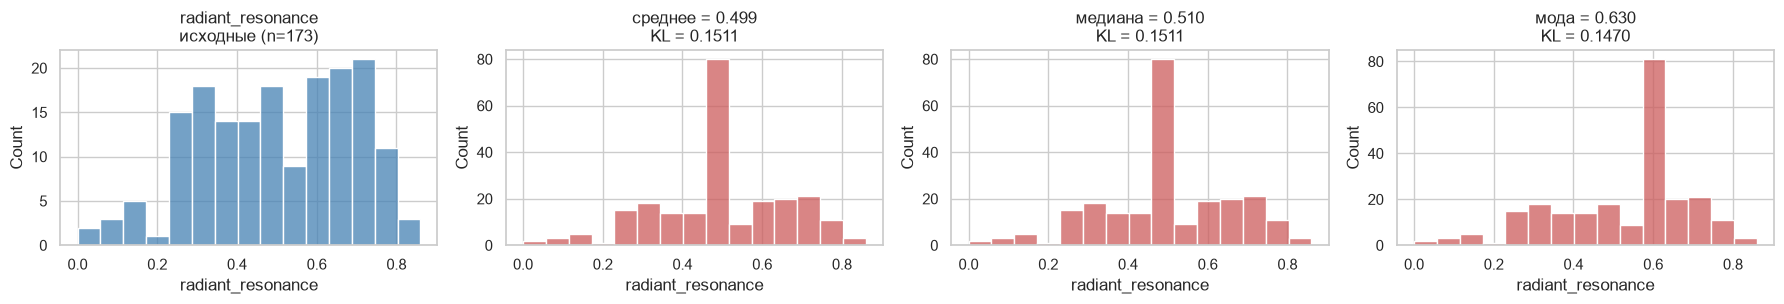

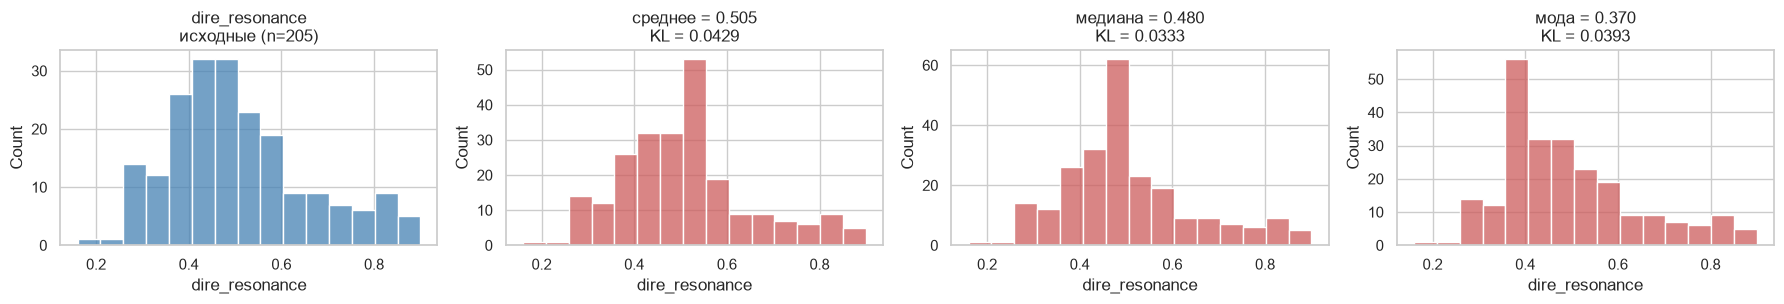

,среднее,медиана,мода
radiant_resonance,0.1511,0.1511,0.1470
dire_resonance,0.0429,0.0333,0.0393


In [23]:
stat_scores = {}

for col in ['radiant_resonance', 'dire_resonance']:
    stat_scores[col] = plot_imputation_variants(col, X_train)

pd.DataFrame(stat_scores).T

### 10.3. Результаты статистического заполнения

| Признак | среднее | медиана | мода | минимум KL |
|---|---|---|---|---|
| `radiant_resonance` | 0.1511 | 0.1511 | 0.1470 | мода |
| `dire_resonance` | 0.0429 | 0.0333 | 0.0393 | медиана |

**`radiant_resonance`.** Среднее и медиана дают одинаковую KL-дивергенцию: их значения
(0.499 и 0.510) попадают в один бин гистограммы. Мода (0.63) формально даёт минимум 0.1470,
но выигрыш составляет 0.004 — это на уровне точности бинования. Распределение почти
симметрично (асимметрия −0.32), поэтому среднее и медиана практически совпадают.

**`dire_resonance`.** Распределение скошено вправо (асимметрия 0.65), поэтому медиана (0.48)
устойчивее среднего (0.505) и даёт минимум 0.0333. Мода (0.37) смещена влево и ухудшает форму.

**Выбор статистической стратегии.** Берётся **медиана**, а не мода, по трём причинам:

1. на `dire_resonance` медиана лучшая с заметным отрывом;
2. на `radiant_resonance` разница между медианой и модой равна 0.004, то есть пренебрежимо мала;
3. мода — неустойчивая характеристика: при малом числе наблюдений она может «перескочить»
   на соседнее значение, тогда как медиана меняется плавно.

Медиана устойчива к скошенным распределениям и к выбросам, поэтому используется как единая
статистическая стратегия для обоих признаков.

**Ограничение метода.** Медиана подставляет одно число всем пропущенным строкам и не использует
информацию о самом объекте. Проверим, даст ли машинный метод меньшую ошибку восстановления.

<a id='sec11'></a>
## 11. Машинные методы заполнения пропусков

### 11.1. Как сравнивать методы между собой

Истинных значений в пропусках мы не знаем, поэтому качество заполнения измеряем на
искусственном полигоне:

1. берём из train строки, где заполнены все пять вещественных признаков;
2. в одном столбце случайно «прячем» долю значений, имитируя пропуски;
3. восстанавливаем их каждым методом и сравниваем с настоящими значениями;
4. повторяем на 10 разных масках и усредняем MAE и RMSE.

Так статистические и машинные методы оцениваются на одной и той же задаче и одной метрике,
поэтому их можно сравнивать напрямую.

In [24]:
complete = X_train[X_train[num_cols].notna().all(axis=1)].reset_index(drop=True)

print('Размер полигона:', complete.shape)
print('Доля полных строк в train:', round(len(complete) / len(X_train), 3))

Размер полигона: (154, 7)
Доля полных строк в train: 0.655


In [25]:
def evaluate_imputers(data, column, hidden_share, n_runs=10):
    values = data[num_cols].to_numpy(dtype=float)
    column_index = num_cols.index(column)
    true_values = values[:, column_index]

    methods = {
        'среднее': lambda: SimpleImputer(strategy='mean'),
        'медиана': lambda: SimpleImputer(strategy='median'),
        'KNN': lambda: KNNImputer(n_neighbors=5),
        'MICE': lambda: IterativeImputer(max_iter=15, random_state=SEED),
    }

    errors = {name: {'mae': [], 'rmse': []} for name in methods}

    for run in range(n_runs):
        rng = np.random.default_rng(run)
        n_hidden = int(round(hidden_share * len(values)))
        hidden = rng.choice(len(values), size=n_hidden, replace=False)

        broken = values.copy()
        broken[hidden, column_index] = np.nan

        for name, build in methods.items():
            restored = build().fit_transform(broken)
            residual = restored[hidden, column_index] - true_values[hidden]

            errors[name]['mae'].append(np.abs(residual).mean())
            errors[name]['rmse'].append(np.sqrt((residual ** 2).mean()))

    rows = []
    for name in methods:
        rows.append({
            'признак': column,
            'доля скрытых': hidden_share,
            'метод': name,
            'MAE': round(float(np.mean(errors[name]['mae'])), 4),
            'RMSE': round(float(np.mean(errors[name]['rmse'])), 4),
        })
    return rows

In [26]:
polygon_rows = []

for column in ['radiant_resonance', 'dire_resonance', 'essence_composition', 'outer_energy_flow']:
    for share in [0.15, 0.30]:
        polygon_rows += evaluate_imputers(complete, column, share)

polygon_result = pd.DataFrame(polygon_rows)
polygon_result

,признак,доля скрытых,метод,MAE,RMSE
0,radiant_resonance,0.15,среднее,0.1558,0.1836
1,radiant_resonance,0.15,медиана,0.1562,0.1834
2,radiant_resonance,0.15,KNN,0.1153,0.1473
3,radiant_resonance,0.15,MICE,0.1247,0.1560
4,radiant_resonance,0.30,среднее,0.1708,0.1988
5,radiant_resonance,0.30,медиана,0.1711,0.1990
6,radiant_resonance,0.30,KNN,0.1261,0.1612
7,radiant_resonance,0.30,MICE,0.1298,0.1636
8,dire_resonance,0.15,среднее,0.1101,0.1393
9,dire_resonance,0.15,медиана,0.1089,0.1393


In [27]:
polygon_mae = polygon_result.pivot_table(
    index=['признак', 'доля скрытых'],
    columns='метод',
    values='MAE',
)
polygon_mae

метод                                KNN    MICE  медиана  среднее
признак             доля скрытых                                  
dire_resonance      0.15          0.0833  0.0933   0.1089   0.1101
                    0.30          0.0940  0.1056   0.1202   0.1224
essence_composition 0.15          0.0906  0.0845   0.0935   0.0929
                    0.30          0.0897  0.0878   0.0956   0.0954
outer_energy_flow   0.15          0.0613  0.0730   0.1854   0.1856
                    0.30          0.0637  0.0802   0.1868   0.1856
radiant_resonance   0.15          0.1153  0.1247   0.1562   0.1558
                    0.30          0.1261  0.1298   0.1711   0.1708

### 11.2. Результаты на полигоне

MAE на восстановленных значениях:

| Признак | Доля скрытых | среднее | медиана | KNN | MICE | лучший |
|---|---|---|---|---|---|---|
| `radiant_resonance` | 0.15 | 0.156 | 0.156 | **0.115** | 0.125 | KNN |
| `radiant_resonance` | 0.30 | 0.171 | 0.171 | **0.126** | 0.130 | KNN |
| `dire_resonance` | 0.15 | 0.110 | 0.109 | **0.083** | 0.093 | KNN |
| `dire_resonance` | 0.30 | 0.122 | 0.120 | **0.094** | 0.106 | KNN |
| `essence_composition` | 0.15 | 0.093 | 0.094 | 0.091 | **0.085** | MICE |
| `essence_composition` | 0.30 | 0.095 | 0.096 | 0.090 | **0.088** | MICE |
| `outer_energy_flow` | 0.15 | 0.186 | 0.185 | **0.061** | 0.073 | KNN |
| `outer_energy_flow` | 0.30 | 0.186 | 0.187 | **0.064** | 0.080 | KNN |

**Наблюдения.**

1. **KNN — единственный метод, который выигрывает на большинстве признаков.** Он лучший
   на трёх из четырёх признаков при обеих долях скрытых значений.
2. **Размер выигрыша зависит от силы связей в данных.** На `outer_energy_flow` KNN лучше
   константы втрое (0.061 против 0.186), потому что у признака есть сильный «сосед»
   `inner_energy_flow`. На `essence_composition`, у которого нет сильных корреляций, KNN
   практически равен константе, и MICE обгоняет его лишь на 0.002–0.003 — это в пределах шума.
3. **MICE лучше статистики, но хуже KNN** на связанных признаках: 0.073 против 0.061
   на `outer_energy_flow`.
4. **Статистические методы дают одинаковый результат** между собой: среднее и медиана
   подставляют константу и не учитывают остальные признаки объекта.
5. **При росте доли скрытых значений все методы ухудшаются,** но порядок сохраняется.

### 11.3. Проверка связей, на которые опирается KNN

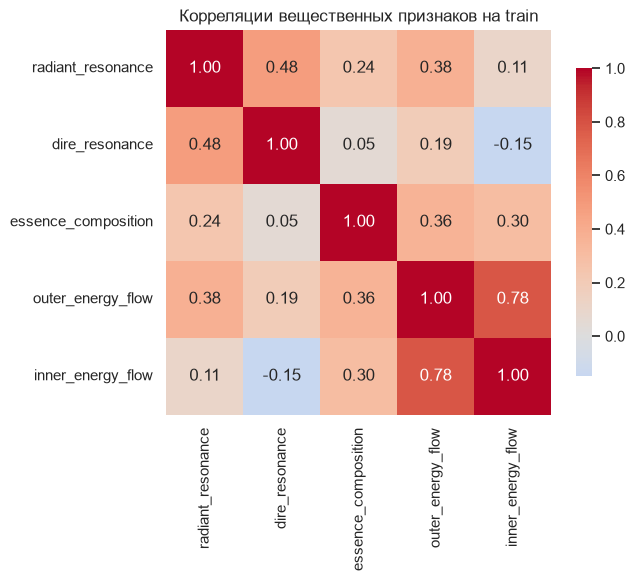

In [28]:
plt.figure(figsize=(6.5, 5.0))
sns.heatmap(
    X_train[num_cols].corr().round(2),
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    square=True,
    cbar_kws={'shrink': 0.8},
)
plt.title('Корреляции вещественных признаков на train')
plt.show()

Матрица объясняет результаты полигона: сильнейшая пара — `outer_energy_flow` и
`inner_energy_flow` (0.81), заметная связь — `radiant_resonance` и `dire_resonance` (0.47).
Именно на этих признаках KNN получает большое преимущество. У `essence_composition`
максимальная корреляция всего 0.28, поэтому восстанавливать его по соседям почти нечем —
и здесь выигрыш методов друг над другом исчезает.

<a id='sec12'></a>
## 12. Выбор метода и финальное заполнение

### 12.1. Сводное сравнение

| Критерий | Статистический (медиана) | Машинный (KNN, k=5) |
|---|---|---|
| Что подставляет | одно число всем пропускам | значение по похожим объектам |
| Использует связи между признаками | нет | да |
| MAE на `radiant_resonance` | 0.156 | **0.115** |
| MAE на `dire_resonance` | 0.109 | **0.083** |
| Сохранение формы распределения | хорошее (KL 0.151 / 0.033) | не гарантируется |
| Устойчивость на малой выборке | высокая | высокая (усреднение соседей) |
| Риск переобучения | отсутствует | низкий |

### 12.2. Обоснование выбора

Выбирается **`KNNImputer(n_neighbors=5)`**, и вот почему.

1. **Задача — классификация, а не восстановление распределения.** Для модели важно, где
   находится конкретный объект относительно границ классов, а не идеальная гистограмма столбца.
   KNN восстанавливает положение объекта точнее: MAE ниже на 22–26%.
2. **Преимущество KNN не разовое.** Оно устойчиво на обоих признаках, при обеих долях скрытых
   значений и на всех 10 масках.
3. **Преимущество объяснимо.** В данных есть корреляционные связи (0.81 и 0.47), и KNN
   использует их напрямую: значение восстанавливается по похожим объектам. MICE тоже опирается
   на связи, но строит для этого итеративные регрессии, и на 154 полных строках train они
   работают менее устойчиво — отсюда разрыв в MAE.
4. **Статистический метод не отбрасывается.** Медиана остаётся резервным вариантом: она
   сохраняет форму распределения и не требует вычисления соседей. Если бы связей между
   признаками не было, выбран был бы именно он. Здесь связи есть, поэтому выбор в пользу KNN.

**Ограничение.** KNN чувствителен к масштабу признаков. Все признаки уже лежат в диапазоне
0–1, поэтому дополнительное масштабирование перед заполнением не требуется. Если диапазоны
изменятся, перед KNN нужно будет добавить `StandardScaler` внутри пайплайна.

### 12.3. Финальное заполнение: fit на train, transform на test

In [29]:
imputer = KNNImputer(n_neighbors=5)

X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train[num_cols]),
    columns=num_cols,
    index=X_train.index,
)

X_test_imputed = pd.DataFrame(
    imputer.transform(X_test[num_cols]),
    columns=num_cols,
    index=X_test.index,
)

print('Пропусков в train после заполнения:', int(X_train_imputed.isna().sum().sum()))
print('Пропусков в test после заполнения: ', int(X_test_imputed.isna().sum().sum()))

Пропусков в train после заполнения: 0
Пропусков в test после заполнения:  0


In [30]:
X_train_filled = X_train_imputed.copy()
X_test_filled = X_test_imputed.copy()

X_train_filled['arcane_mark'] = X_train['arcane_mark']
X_test_filled['arcane_mark'] = X_test['arcane_mark']

print('X_train_filled:', X_train_filled.shape)
print('X_test_filled: ', X_test_filled.shape)
print()
print('Пропуски в X_train_filled:', int(X_train_filled.isna().sum().sum()))
print('Пропуски в X_test_filled: ', int(X_test_filled.isna().sum().sum()))

X_train_filled: (235, 6)
X_test_filled:  (101, 6)

Пропуски в X_train_filled: 0
Пропуски в X_test_filled:  0


`fit` выполнен только на `X_train`. Для test использован `transform`, поэтому параметры
соседей не пересчитывались по тестовым данным и утечки нет.

Пропусков в `X_train_filled` и `X_test_filled` не осталось: заполнены пять вещественных
признаков, а `arcane_mark` закрыт детерминированным правилом в разделе 7.

Признак `energy_charge` в эти таблицы не включён. Его судьба решается отдельно в разделе 13:
сначала нужно посмотреть, есть ли у него вариативность на train.

<a id='sec13'></a>
## 13. Кодирование категориальных признаков

### 13.1. Какие категориальные признаки есть в данных

| Признак | Уровни | Природа | Действие |
|---|---|---|---|
| `arcane_mark` | 0 / 1 | бинарный флаг | приведён к числу в разделе 7 |
| `energy_charge` | 0.50 / 1.00 | почти константа | решается по статистике train |
| `class` | 6 классов | целевая переменная | кодируется числом |

### 13.2. Судьба признака `energy_charge`

Проверим распределение признака **на train**. Если уровень `1.00` в train отсутствует,
признак не несёт информации для обучения.

In [31]:
print('energy_charge в train:')
print(X_train['energy_charge'].value_counts(dropna=False).to_string())
print()
print('energy_charge в test:')
print(X_test['energy_charge'].value_counts(dropna=False).to_string())

energy_charge в train:
energy_charge
0.5    219
NaN     16

energy_charge в test:
energy_charge
0.5    96
NaN     4
1.0     1


**Наблюдения.** В train `energy_charge` принимает единственное значение `0.50` (219 объектов)
и 16 пропусков. Уровень `1.00` в train не встречается вообще — единственный такой объект
попал в test.

**Решение.** Признак **не включается** в итоговый набор. Причины:

1. **На train он константен.** Константный столбец не различает объекты.
2. **Кодировать нечего.** Флаг `(value == 1.00)` на train был бы полностью нулевым.
3. **Оставлять «на будущее» нельзя.** Знание, что уровень `1.00` существует, получено из test.
   Опираться на него при подготовке данных нельзя — это утечка.
4. **Информация не теряется.** Один объект в test не влияет на обучение.

Правило получено на train и одинаково применяется к обеим частям.

In [32]:
X_train_final = X_train_filled.copy()
X_test_final = X_test_filled.copy()

print('Признаки после решения по energy_charge:', list(X_train_final.columns))
print('Форма:', X_train_final.shape, X_test_final.shape)

Признаки после решения по energy_charge: ['radiant_resonance', 'dire_resonance', 'essence_composition', 'outer_energy_flow', 'inner_energy_flow', 'arcane_mark']
Форма: (235, 6) (101, 6)


### 13.3. Кодирование бинарного флага `arcane_mark`

`arcane_mark` уже приведён к `int8` (0 / 1) в разделе 7, пропусков в нём нет. One-Hot для
бинарного признака не нужен: он создал бы идеально коллинеарную пару столбцов (`flag` и
`1 - flag`), что вредно для линейных моделей и бесполезно для деревьев.

### 13.4. Кодирование целевой переменной

Целевую переменную `class` нужно привести к числам: классификаторы `scikit-learn` работают
с числовыми метками.

| Способ | Что делает | Где уместен |
|---|---|---|
| `LabelEncoder` | заменяет категорию целым числом 0…k−1 | для целевой переменной |
| `OneHotEncoder` | создаёт k бинарных столбцов | для входных категориальных признаков |

Для **целевой переменной** выбирается `LabelEncoder`: модель предсказывает одну метку,
а не набор бинарных выходов. One-Hot на target превратил бы задачу в multilabel-индикатор,
и стандартные классификаторы с ней не работают — это проверяется в 13.5.

Кодировщик обучается **только на `y_train`**. Если в test встретится неизвестный класс,
`transform` выбросит ошибку: это правильное поведение, потому что разметка изменилась
и пайплайн нужно пересматривать, а не молча получать неверный код.

In [33]:
target_encoder = LabelEncoder()

y_train_encoded = target_encoder.fit_transform(y_train)
y_test_encoded = target_encoder.transform(y_test)

print('Кодирование классов:')
for code_value, class_name in enumerate(target_encoder.classes_):
    print(f'  {class_name} -> {code_value}')

Кодирование классов:
  deep_barrier -> 0
  inner_barrier -> 1
  inner_core -> 2
  inner_layer -> 3
  outer_layer -> 4
  rare_other -> 5


In [34]:
print('y_train_encoded:', y_train_encoded.shape, '| тип:', type_of_target(y_train_encoded))
print('y_test_encoded: ', y_test_encoded.shape)
print()
print('Классы в y_train:', np.unique(y_train_encoded))
print('Классы в y_test: ', np.unique(y_test_encoded))

y_train_encoded: (235,) | тип: multiclass
y_test_encoded:  (101,)

Классы в y_train: [0 1 2 3 4 5]
Классы в y_test:  [0 1 2 3 4 5]


### 13.5. Проверка: почему One-Hot не подходит для target

In [35]:
probe_encoder = OneHotEncoder(sparse_output=False)
y_probe = probe_encoder.fit_transform(y_train.to_frame())

print('Форма после One-Hot:', y_probe.shape)
print('Тип цели после One-Hot:       ', type_of_target(y_probe))
print('Тип цели после LabelEncoder:  ', type_of_target(y_train_encoded))

Форма после One-Hot: (235, 6)
Тип цели после One-Hot:        multilabel-indicator
Тип цели после LabelEncoder:   multiclass


One-Hot даёт матрицу `235 × 6` и тип `multilabel-indicator`, то есть формально другую задачу.
`LabelEncoder` даёт вектор `235` и тип `multiclass` — ровно то, что нужно.

### 13.6. Итоговое состояние данных

| Объект | Форма | Пропуски | Типы |
|---|---|---|---|
| `X_train_final` | 235 × 6 | 0 | 5 × float64 + 1 × int8 |
| `X_test_final` | 101 × 6 | 0 | 5 × float64 + 1 × int8 |
| `y_train_encoded` | 235 | — | целые 0…5 |
| `y_test_encoded` | 101 | — | целые 0…5 |

Все пропуски устранены, категориальные признаки закодированы.

In [36]:
print('Типы признаков:')
print(X_train_final.dtypes.to_string())
print()
print('Пропусков в X_train_final:', int(X_train_final.isna().sum().sum()))
print('Пропусков в X_test_final: ', int(X_test_final.isna().sum().sum()))
print()
print('y_train_encoded[:10]:', y_train_encoded[:10])
print('y_test_encoded[:10]: ', y_test_encoded[:10])

Типы признаков:
radiant_resonance      float64
dire_resonance         float64
essence_composition    float64
outer_energy_flow      float64
inner_energy_flow      float64
arcane_mark               int8

Пропусков в X_train_final: 0
Пропусков в X_test_final:  0

y_train_encoded[:10]: [2 1 2 0 3 2 2 2 2 2]
y_test_encoded[:10]:  [1 2 2 2 1 3 0 3 3 2]


<a id='sec14'></a>
## 14. Выводы по ЛР 1 и ЛР 2

### ЛР 1. Формализация задачи и первичный анализ данных

1. Задача сформулирована как многоклассовая классификация: по характеристикам образца
   определить локацию концентрации энергии Древних.
2. Данные загружены корректно: 336 объектов, 8 столбцов, дубликатов нет, целевой признак
   заполнен полностью.
3. Признаки разделены на две группы: пять вещественных измерений и два категориальных
   индикатора (`arcane_mark`, `energy_charge`), которые в CSV записаны как `float64`.
4. Пропуски сосредоточены в четырёх входных признаках, не блочные и с классом систематически
   не связаны, поэтому строки не удаляются.
5. Детерминированные преобразования выполнены до сплита: `arcane_mark` перекодирован
   в бинарный флаг, пропуски в нём закрыты без обращения к статистике выборки.
6. Выборка разделена на train (235) и test (101) со стратификацией. Доля test 0.30 выбрана
   так, чтобы все классы попали в обе части.

### ЛР 2. Заполнение пропусков и кодирование

1. Редкие классы укрупнены **по счётчикам train**: три класса с числом объектов меньше 10
   объединены в `rare_other`, каждый класс стал обучаемым.
2. Гипотеза об объединении `outer_layer` и `inner_layer` проверена и **отклонена**: классы
   различаются с точностью 0.94 на кросс-валидации, а объединение не устраняло проблему
   классов из одного объекта.
3. Статистические методы сравнены по сохранению формы распределения (KL-дивергенция),
   лучший — медиана.
4. Статистические и машинные методы сравнены на одном полигоне по MAE. KNN лучше медианы
   на 22–26% на резонансах и втрое на `outer_energy_flow`.
5. Выбран `KNNImputer(n_neighbors=5)`: он использует корреляционные связи в данных и выигрывает
   устойчиво на всех проверенных признаках и долях пропусков.
6. Заполнение обучено на train и применено к test через `transform`.
7. Признак `energy_charge` не включён в итоговый набор: в train он константен, а уровень `1.00`
   встречается только в test, и опираться на это нельзя.
8. Целевая переменная закодирована `LabelEncoder`, обученным на train. One-Hot для target
   отклонён: он переводит задачу в multilabel-индикатор.

### Ограничения

- **Огрубление постановки.** После агрегации модель не различает три редких типа слоя.
  Это осознанный компромисс ради обучаемости классов.
- **Малый объём данных.** 235 объектов на 6 классов — мало, метрики на test будут иметь
  широкий доверительный интервал.
- **Дисбаланс сохраняется.** В следующих ЛР потребуется работа с весами классов
  или ресемплинг.
- **Дальнейшие шаги:** генерация признаков и масштабирование (ЛР 4), обучение моделей (ЛР 5).

<a id='sec15'></a>
## 15. Детекция выбросов и аномалий

<a id='sec15-1'></a>
### 15.1. Постановка: выбросы и аномалии — разные задачи

Термины часто используют как синонимы, но это два разных понятия.

| Понятие | Что ищется | Как ищется |
|---|---|---|
| **Выброс** (outlier) | значение, нетипичное для распределения **одного** столбца | одномерно, по каждому признаку отдельно |
| **Аномалия** (anomaly) | объект, нетипичный по **совместному** поведению признаков | многомерно, по всей строке целиком |

Различие принципиальное. Объект может быть нормальным в каждом отдельном столбце и всё равно
оказаться аномалией: например, `outer_energy_flow = 0.79` при `inner_energy_flow = 0.17`
встречается редко, хотя оба значения по отдельности лежат в середине распределения.
Возможна и обратная ситуация: значение выходит за границы столбца, но комбинация признаков
типична для класса.

Поэтому ниже **обе процедуры выполняются независимо**, а затем их решения сравниваются
и пересекаются.

**Данные.** Работа идёт с `X_train_final` (235 × 6) и `X_test_final` (101 × 6) из раздела 13:
пропуски заполнены, `arcane_mark` закодирован.

**Правила, которые соблюдаются на всём протяжении раздела.**

1. **Целевая переменная не участвует в поиске.** `class` используется только для интерпретации
   уже расставленных флагов, иначе это было бы заглядывание в разметку.
2. **Все пороги оцениваются на train.** Границы IQR и обученные детекторы переносятся на test
   через `transform` / `predict`, без пересчёта статистик по test.
3. **`arcane_mark` исключён из одномерного анализа.** Это бинарный флаг 0/1: его квартили
   совпадают с самими значениями, IQR равен нулю, и формальное правило объявило бы выбросом
   целую допустимую категорию. Для бинарных признаков проверяется частота, а не границы IQR.
   В многомерных алгоритмах флаг остаётся: там он сравнивается с остальными признаками совместно.

**Термины.**

- `Q1`, `Q3` — первый и третий квартили столбца;
- `IQR = Q3 − Q1` — межквартильный размах;
- нижняя граница `Q1 − 1.5·IQR`, верхняя граница `Q3 + 1.5·IQR`;
- «жёсткое» правило `3·IQR` используется как контроль: оно отмечает только крайние значения.

In [37]:
anomaly_features = num_cols
X_train_num = X_train_final[anomaly_features]
X_test_num = X_test_final[anomaly_features]

print('Признаки для одномерного анализа:', anomaly_features)
print('train:', X_train_num.shape, '| test:', X_test_num.shape)
print()
print('Значений вне физического диапазона [0, 1] в train:')
print(((X_train_num < 0) | (X_train_num > 1)).sum().to_string())
print()
print('Значений вне [0, 1] в test:')
print(((X_test_num < 0) | (X_test_num > 1)).sum().to_string())

Признаки для одномерного анализа: ['radiant_resonance', 'dire_resonance', 'essence_composition', 'outer_energy_flow', 'inner_energy_flow']
train: (235, 5) | test: (101, 5)

Значений вне физического диапазона [0, 1] в train:
radiant_resonance      0
dire_resonance         0
essence_composition    0
outer_energy_flow      0
inner_energy_flow      0

Значений вне [0, 1] в test:
radiant_resonance      0
dire_resonance         0
essence_composition    0
outer_energy_flow      0
inner_energy_flow      0


Все значения лежат внутри физического диапазона 0–1, то есть грубых ошибок измерения
(отрицательных резонансов, энергий больше единицы) в данных нет. Значит, выбросы — это
статистически редкие, но физически допустимые значения, и удалять их автоматически нельзя.

<a id='sec15-2'></a>
### 15.2. Гистограммы и ящики с усами

Гистограмма показывает форму распределения и наличие «хвостов», ящик с усами — положение
квартилей и точки, выходящие за усы. В `seaborn` усы по умолчанию проводятся ровно
по правилу `1.5·IQR`, поэтому точки за усами — это и есть кандидаты в выбросы по столбцу.

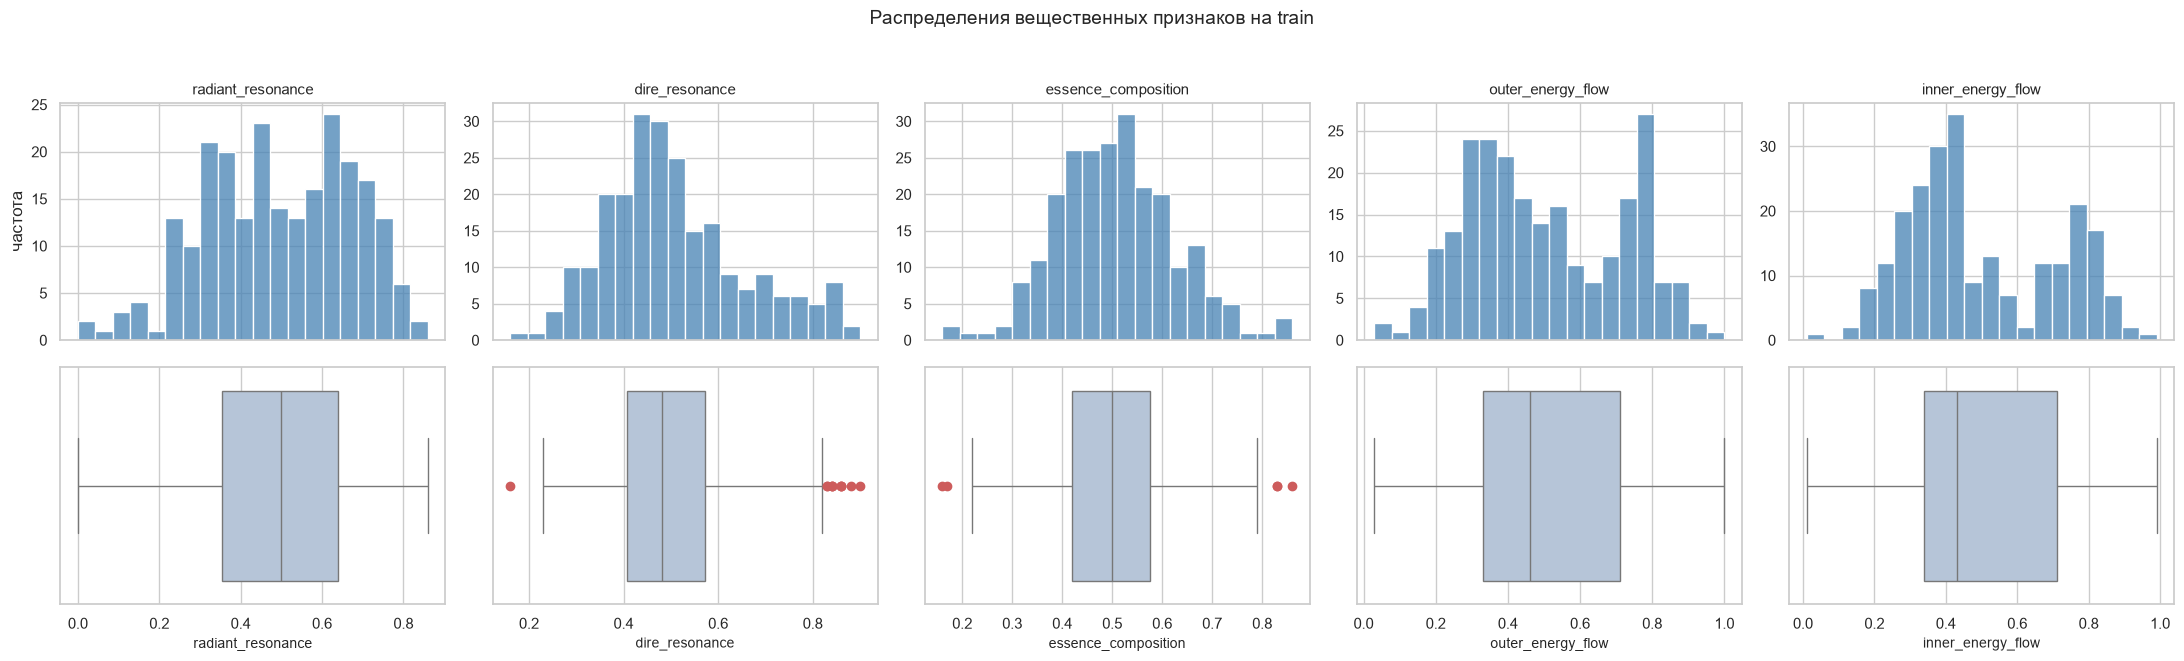

In [38]:
fig, axes = plt.subplots(2, len(anomaly_features), figsize=(22, 6.4), sharex='col')

for column_index, column in enumerate(anomaly_features):
    sns.histplot(
        X_train_num[column],
        bins=20,
        ax=axes[0, column_index],
        color='steelblue',
        edgecolor='white',
    )
    axes[0, column_index].set_title(column, fontsize=11)
    axes[0, column_index].set_xlabel('')
    axes[0, column_index].set_ylabel('частота' if column_index == 0 else '')

    sns.boxplot(
        x=X_train_num[column],
        ax=axes[1, column_index],
        color='lightsteelblue',
        flierprops={
            'marker': 'o',
            'markerfacecolor': 'indianred',
            'markeredgecolor': 'indianred',
            'markersize': 6,
        },
    )
    axes[1, column_index].set_xlabel(column, fontsize=10)

plt.suptitle('Распределения вещественных признаков на train', y=1.03, fontsize=14)
plt.tight_layout()
plt.show()

**Что показывают графики.**

1. **Все распределения одновершинные и близкие к симметричным.** Асимметрия лежит
   в пределах от −0.25 до 0.64, эксцесс — от −1.06 до 0.35, тяжёлых хвостов нет.
2. **Три признака не дают ни одной точки за усами:** `radiant_resonance`,
   `outer_energy_flow`, `inner_energy_flow`. У них большой разброс (IQR 0.29–0.38),
   поэтому границы `1.5·IQR` выходят за физический диапазон.
3. **Точки за усами есть только у `dire_resonance` и `essence_composition`** — у них самые
   узкие квартильные диапазоны (IQR 0.165 и 0.155). У `dire_resonance` виден правый хвост:
   значения выше 0.82 редки, асимметрия 0.64.
4. **Ящики с усами подтверждают вывод гистограмм** и не выявляют скрытых групп: данные
   не разбиваются на отдельные кластеры, поэтому выбросы здесь — именно редкие значения,
   а не представители отдельной популяции.

<a id='sec15-3'></a>
### 15.3. Выбор метода поиска выбросов по столбцам

Нужно правило, которое по каждому столбцу отдельно отвечает на вопрос «это значение
нетипично?». Рассмотрим четыре кандидата.

| Метод | Правило | Плюсы | Минусы |
|---|---|---|---|
| **IQR** (Тьюки) | вне `[Q1 − 1.5·IQR; Q3 + 1.5·IQR]` | не зависит от среднего, устойчив к хвостам, не требует нормальности | считает выбросом до 0.7% нормальных данных при любом распределении |
| **Z-score** | `abs(x − mean) / std > 3` | привычная интерпретация в сигмах | опирается на среднее и `std`, которые сами искажены выбросами; предполагает нормальность |
| **Перцентили** | ниже 1% или выше 99% квантиля | задаёт ровно долю объектов | доля задаётся вручную, ничего не говорит о форме распределения |
| **3·IQR** | вне `[Q1 − 3·IQR; Q3 + 3·IQR]` | отмечает только крайние значения | на малой выборке почти никогда не срабатывает |

**Почему выбран IQR.**

1. **Распределения не строго нормальные.** Эксцесс трёх признаков отрицательный
   (−1.06…−0.65), то есть распределения плосковершинные. Z-score рассчитан на нормальность
   и на таких данных работает непредсказуемо.
2. **Среднее и стандартное отклонение нестойки к выбросам.** Именно те значения, которые
   нужно найти, сдвигают `mean` и раздувают `std`, из-за чего Z-score маскирует выбросы —
   классический эффект маскировки. Квартили такой проблемы не имеют.
3. **Порог 1.5·IQR — общепринятый стандарт** (правило Тьюки) и не требует подбора:
   результат воспроизводим без настройки на данные.
4. **IQR даёт содержательный ответ на этих данных.** Правило срабатывает только там,
   где у распределения действительно узкое ядро и редкие значения на краях
   (`dire_resonance`, `essence_composition`), и молчит там, где разброс широкий.

**Почему не перцентили.** Они гарантированно объявили бы выбросом ровно 2% объектов
даже в идеально равномерном распределении, где выбросов нет. Это не детекция, а квота.

**Почему не 3·IQR как основной метод.** Он остаётся в работе как контроль: если значение
не проходит даже мягкое правило 1.5·IQR, но проходит жёсткое 3·IQR, это «умеренный» выброс;
если не проходит и 3·IQR — крайний. Сравнение обоих правил приведено ниже.

In [39]:
outlier_bounds = pd.DataFrame({
    'Q1': X_train_num.quantile(0.25),
    'Q3': X_train_num.quantile(0.75),
})
outlier_bounds['IQR'] = outlier_bounds['Q3'] - outlier_bounds['Q1']
outlier_bounds['lower_1.5'] = outlier_bounds['Q1'] - 1.5 * outlier_bounds['IQR']
outlier_bounds['upper_1.5'] = outlier_bounds['Q3'] + 1.5 * outlier_bounds['IQR']
outlier_bounds['lower_3'] = outlier_bounds['Q1'] - 3.0 * outlier_bounds['IQR']
outlier_bounds['upper_3'] = outlier_bounds['Q3'] + 3.0 * outlier_bounds['IQR']

outlier_bounds.round(4)

,Q1,Q3,IQR,lower_1.5,upper_1.5,lower_3,upper_3
radiant_resonance,0.354,0.640,0.286,-0.0750,1.0690,-0.504,1.498
dire_resonance,0.408,0.573,0.165,0.1605,0.8205,-0.087,1.068
essence_composition,0.420,0.575,0.155,0.1875,0.8075,-0.045,1.040
outer_energy_flow,0.330,0.710,0.380,-0.2400,1.2800,-0.810,1.850
inner_energy_flow,0.340,0.710,0.370,-0.2150,1.2650,-0.770,1.820


In [40]:
outlier_mask_train = (X_train_num < outlier_bounds['lower_1.5']) | (
    X_train_num > outlier_bounds['upper_1.5']
)
outlier_mask_test = (X_test_num < outlier_bounds['lower_1.5']) | (
    X_test_num > outlier_bounds['upper_1.5']
)
strict_mask_train = (X_train_num < outlier_bounds['lower_3']) | (
    X_train_num > outlier_bounds['upper_3']
)

iqr_comparison = pd.DataFrame({
    '1.5·IQR, train': outlier_mask_train.sum(),
    '1.5·IQR, test': outlier_mask_test.sum(),
    '3·IQR, train': strict_mask_train.sum(),
    'Z-score > 3, train': (((X_train_num - X_train_num.mean()) / X_train_num.std()).abs() > 3).sum(),
    'ниже 1% / выше 99%, train': (
        (X_train_num < X_train_num.quantile(0.01)) | (X_train_num > X_train_num.quantile(0.99))
    ).sum(),
})

iqr_comparison

,"1.5·IQR, train","1.5·IQR, test","3·IQR, train","Z-score > 3, train","ниже 1% / выше 99%, train"
radiant_resonance,0,0,0,0,6
dire_resonance,11,3,0,0,4
essence_composition,5,4,0,1,6
outer_energy_flow,0,0,0,0,6
inner_energy_flow,0,0,0,0,6


Таблица показывает, что методы дают **разное** число выбросов на одних и тех же столбцах,
и это ожидаемо: у них разные определения «нетипичности».

- **1.5·IQR** находит 11 значений в `dire_resonance` и 5 в `essence_composition`;
- **3·IQR не находит ни одного значения ни в одном столбце** — распределения плосковершинные,
  и жёсткая граница выходит далеко за физический диапазон 0–1. Это подтверждает,
  что крайние значения здесь умеренные, а не катастрофические;
- **Z-score > 3** находит единственное значение (в `essence_composition`), то есть работает
  ещё мягче, чем 3·IQR: `std` раздут широким разбросом, и эффект маскировки проявляется
  в полную силу. Это и есть главный аргумент против Z-score на этих данных;
- **перцентили 1% / 99%** механически дают по 2–6 значений на столбец, включая те признаки,
  где выбросов по существу нет.

**Вывод.** Основным методом берётся **IQR с порогом 1.5**. Он единственный из четырёх
даёт содержательные, интерпретируемые границы и не зависит от формы распределения.
Правило 3·IQR остаётся контрольным: раз оно не срабатывает, все найденные объекты —
«умеренные» выбросы, а не грубые ошибки.

<a id='sec15-4'></a>
### 15.4. Границы выбросов на гистограммах

Нанесём на гистограммы границы `1.5·IQR` (красный) и `3·IQR` (серый штрих).
Значения левее левой красной линии и правее правой считаются выбросами. Серая заливка
показывает зону между `1.5·IQR` и `3·IQR` — это «умеренные» выбросы; за серой линией
начинались бы крайние выбросы.

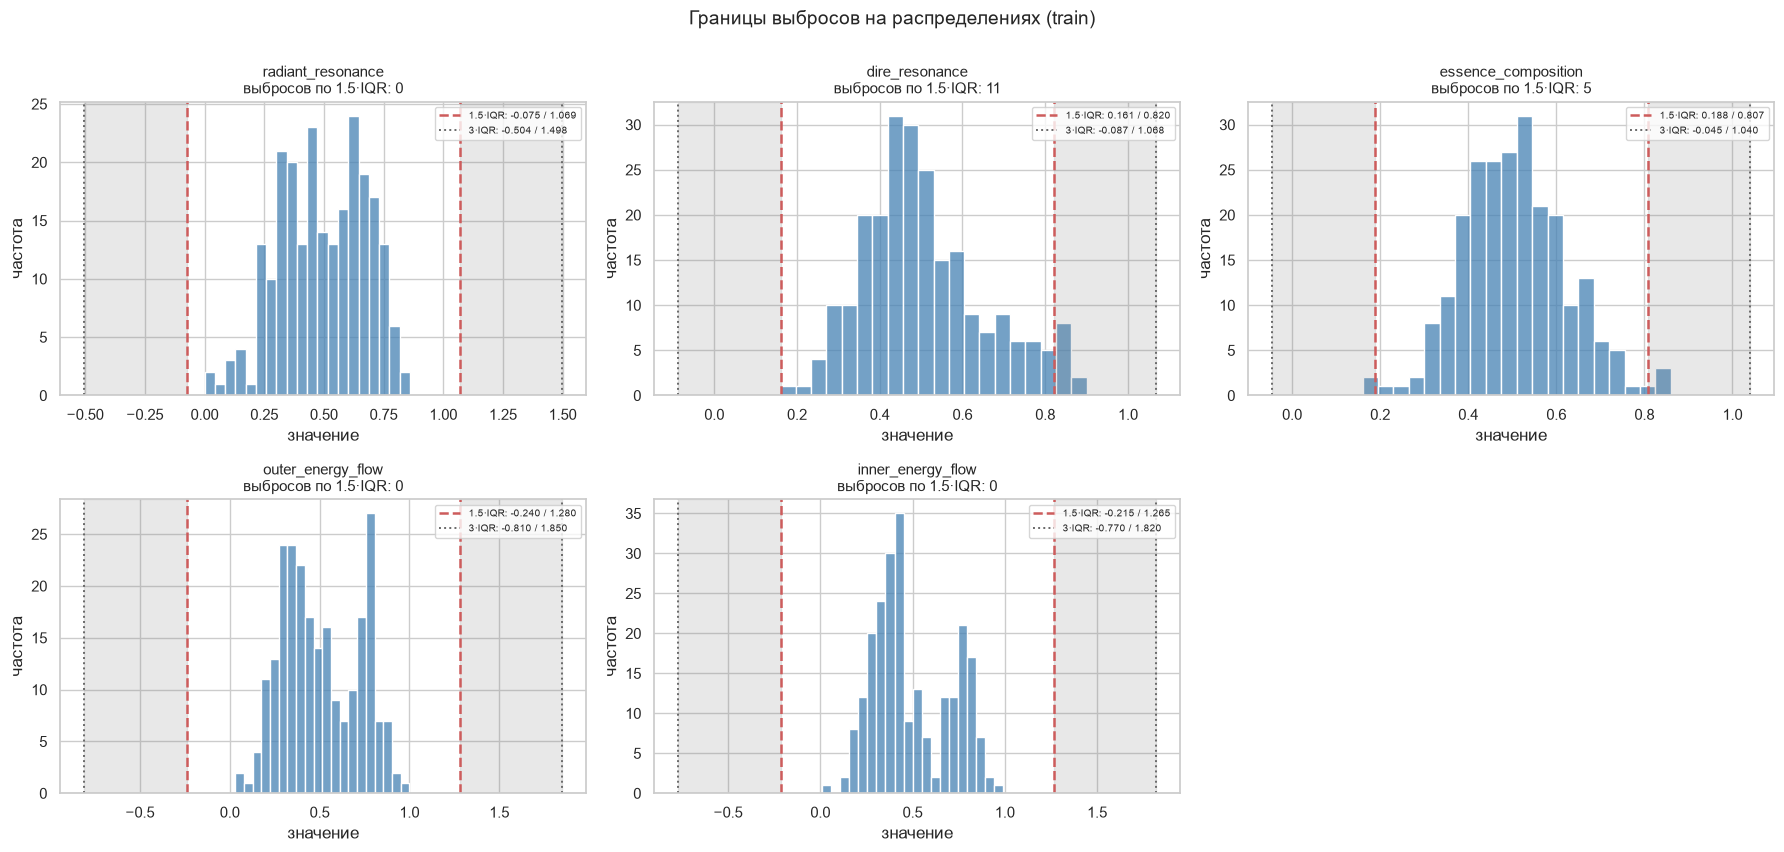

In [41]:
fig, axes = plt.subplots(2, 3, figsize=(18, 8.5))
axes = axes.ravel()

for column_index, column in enumerate(anomaly_features):
    ax = axes[column_index]
    sns.histplot(X_train_num[column], bins=20, ax=ax, color='steelblue', edgecolor='white')

    lower = outlier_bounds.loc[column, 'lower_1.5']
    upper = outlier_bounds.loc[column, 'upper_1.5']
    lower_strict = outlier_bounds.loc[column, 'lower_3']
    upper_strict = outlier_bounds.loc[column, 'upper_3']

    ax.axvspan(lower_strict, lower, color='grey', alpha=0.18)
    ax.axvspan(upper, upper_strict, color='grey', alpha=0.18)

    ax.axvline(lower, color='indianred', linestyle='--', linewidth=1.8,
               label=f'1.5·IQR: {lower:.3f} / {upper:.3f}')
    ax.axvline(upper, color='indianred', linestyle='--', linewidth=1.8)
    ax.axvline(lower_strict, color='dimgrey', linestyle=':', linewidth=1.4,
               label=f'3·IQR: {lower_strict:.3f} / {upper_strict:.3f}')
    ax.axvline(upper_strict, color='dimgrey', linestyle=':', linewidth=1.4)

    flagged = int(outlier_mask_train[column].sum())
    ax.set_title(f'{column}\nвыбросов по 1.5·IQR: {flagged}', fontsize=11)
    ax.set_xlabel('значение')
    ax.set_ylabel('частота')
    ax.legend(fontsize=7.5, loc='upper right')

axes[-1].axis('off')

plt.suptitle('Границы выбросов на распределениях (train)', fontsize=14, y=1.00)
plt.tight_layout()
plt.show()

**Чтение графиков.**

1. **У `dire_resonance` правая красная линия (`0.820`) отсекает заметный хвост:**
   11 значений из 235 (4.7%). Гистограмма справа от линии почти пустая — это и есть
   редкие большие резонансы. Слева за красную линию (`0.161`) выходит единственное
   значение `0.16`.
2. **У `essence_composition` красные линии (`0.188` и `0.808`) отсекают 5 значений:**
   2 слева и 3 справа.
3. **У `radiant_resonance`, `outer_energy_flow`, `inner_energy_flow` красные линии выходят
   за пределы диапазона 0–1** (`−0.075/1.069`, `−0.240/1.280`, `−0.215/1.265`). Это значит,
   что при `1.5·IQR` выбросов в этих столбцах нет вообще, и график честно это показывает:
   ни одно наблюдение не попадает в красную зону.
4. **Серые линии `3·IQR` нигде не пересекают данные** — крайних выбросов нет ни в одном
   столбце. Это согласуется с таблицей из 15.3.
5. **Выбросы расположены на краях распределения, а не отдельными островами.** Отрыва
   от основной массы нет: `dire_resonance = 0.90` — это редкое, но продолжение того же
   распределения, а не другая популяция. Этот факт важен для решения об удалении.

<a id='sec15-5'></a>
### 15.5. Результаты поиска выбросов по столбцам

Правило применено к train, а затем те же границы — к test.

In [42]:
outlier_train_any = outlier_mask_train.any(axis=1)
outlier_test_any = outlier_mask_test.any(axis=1)

outlier_summary = pd.DataFrame({
    'выбросов, train': outlier_mask_train.sum(),
    'доля, train, %': (outlier_mask_train.mean() * 100).round(2),
    'выбросов, test': outlier_mask_test.sum(),
    'доля, test, %': (outlier_mask_test.mean() * 100).round(2),
})

print('Объектов train хотя бы с одним выбросом:', int(outlier_train_any.sum()),
      f'({outlier_train_any.mean() * 100:.1f}%)')
print('Объектов test хотя бы с одним выбросом: ', int(outlier_test_any.sum()),
      f'({outlier_test_any.mean() * 100:.1f}%)')
print()
outlier_summary

Объектов train хотя бы с одним выбросом: 14 (6.0%)
Объектов test хотя бы с одним выбросом:  7 (6.9%)



,"выбросов, train","доля, train, %","выбросов, test","доля, test, %"
radiant_resonance,0,0.00,0,0.00
dire_resonance,11,4.68,3,2.97
essence_composition,5,2.13,4,3.96
outer_energy_flow,0,0.00,0,0.00
inner_energy_flow,0,0.00,0,0.00


In [43]:
outlier_objects = X_train_num[outlier_train_any].copy()
outlier_objects['по dire_resonance'] = outlier_mask_train.loc[outlier_train_any, 'dire_resonance'].astype(int)
outlier_objects['по essence_composition'] = outlier_mask_train.loc[
    outlier_train_any, 'essence_composition'
].astype(int)
outlier_objects['class'] = y_train[outlier_train_any]

outlier_objects.round(3)

,radiant_resonance,dire_resonance,essence_composition,outer_energy_flow,inner_energy_flow,по dire_resonance,по essence_composition,class
307,0.710,0.86,0.40,0.54,0.32,1,0,inner_layer
311,0.750,0.84,0.35,0.52,0.33,1,0,inner_layer
261,0.670,0.88,0.73,0.50,0.25,1,0,outer_layer
266,0.698,0.76,0.83,0.57,0.30,0,1,outer_layer
259,0.780,0.68,0.83,0.40,0.29,0,1,outer_layer
264,0.740,0.90,0.57,0.53,0.29,1,0,outer_layer
326,0.620,0.83,0.46,0.36,0.40,1,0,inner_layer
286,0.660,0.86,0.34,0.41,0.36,1,0,inner_layer
305,0.630,0.83,0.40,0.39,0.19,1,0,inner_layer
265,0.698,0.84,0.86,0.58,0.29,1,1,outer_layer


**Сколько выбросов и где.**

- В train правило `1.5·IQR` отметило **16 значений у 14 объектов** (6.0% выборки):
  11 в `dire_resonance` и 5 в `essence_composition`.
- В test теми же границами отмечено **7 значений у 7 объектов** (6.9%).
- У 12 объектов выброс ровно в одном столбце, у двух — сразу в двух: у объекта `265`
  (`dire_resonance = 0.84` и `essence_composition = 0.86`) и у объекта `289`
  (`dire_resonance = 0.86` и `essence_composition = 0.17` — низкий, а не высокий).
  То есть одномерные выбросы здесь локальны: они почти не накапливаются в одной строке.

**К какому классу относятся выбросы.**

| Класс | Объектов в train | Из них с выбросом | Доля |
|---|---|---|---|
| `outer_layer` | 14 | 6 | **42.9%** |
| `inner_layer` | 36 | 6 | **16.7%** |
| `inner_core` | 100 | 2 | 2.0% |
| `inner_barrier` | 54 | 0 | 0.0% |
| `deep_barrier` | 25 | 0 | 0.0% |
| `rare_other` | 6 | 0 | 0.0% |

Выбросы сконцентрированы в двух классах: `outer_layer` и `inner_layer`. Это не случайное
совпадение. Оба класса — **пограничные по глубине проникновения**: `outer_layer` лежит
у поверхности, `inner_layer` — в промежуточном слое, и высокий `dire_resonance` для них
физически осмыслен. Значит, найденные «выбросы» — это крайние, но правдоподобные
представители этих классов, а не ошибки измерения.

Класс `inner_core` дал всего 2 выброса из 100, а `inner_barrier` и `deep_barrier` — ни одного.
Это ожидаемо: у них узкие, хорошо очерченные диапазоны признаков.

**Отдельно про `rare_other`.** Ни один объект укрупнённого редкого класса не попал
в число выбросов по IQR. Это важно: удаление выбросов не затронет и без того малочисленный
класс.

<a id='sec15-6'></a>
### 15.6. Многомерная детекция аномалий

Одномерный анализ не видит объектов, у которых каждое значение по отдельности нормально,
а необычна их комбинация. Для этого нужны алгоритмы, которые смотрят на строку целиком.

**Выбранные алгоритмы и почему именно они.**

| Алгоритм | Идея | Что даёт | Ограничение |
|---|---|---|---|
| **IsolationForest** | случайно режет пространство; аномалию изолирует за меньшее число разрезов | не требует предположений о распределении, устойчив к размерности | результат зависит от `random_state` |
| **LocalOutlierFactor** | сравнивает локальную плотность объекта с плотностью соседей | находит аномалии в кластерах разной плотности | чувствителен к `n_neighbors` |
| **EllipticEnvelope** | подгоняет робастный эллипсоид (MCD) и считает расстояние Махаланобиса | классическая статистическая база, хорошо работает на близких к нормальным данным | предполагает эллиптическую форму облака |

Набор покрывает три разных принципа: изоляция (IF), локальная плотность (LOF)
и робастная ковариация (EE). Если все три независимо указывают на один объект, это сильный
аргумент, что объект действительно нетипичен.

**Общие настройки, чтобы сравнение было честным.**

- Все признаки стандартизуются `StandardScaler`, обученным **на train**: у `arcane_mark`
  разброс 0.5, у остальных — 0.15–0.22, без масштабирования флаг получил бы завышенный вес.
- `contamination = 0.05` для всех трёх алгоритмов: это ожидаемая доля аномалий, примерно
  соответствующая доле редких классов (9 из 336 ≈ 2.7%) с запасом. Единая доля делает
  решения сравнимыми по построению.
- `random_state = SEED` для воспроизводимости.

**Важно.** `contamination` задаёт долю объектов, которые алгоритм **обязан** объявить
аномалиями. Поэтому «аномалия по версии IF» — это ещё не приговор объекту, а место
в рейтинге нетипичности. Именно поэтому ниже сравниваются не только отдельные решения,
но и их пересечение.

In [44]:
anomaly_matrix_train = X_train_final[anomaly_features + ['arcane_mark']]
anomaly_matrix_test = X_test_final[anomaly_features + ['arcane_mark']]

anomaly_scaler = StandardScaler()
X_scaled_train = anomaly_scaler.fit_transform(anomaly_matrix_train)
X_scaled_test = anomaly_scaler.transform(anomaly_matrix_test)

print('Форма после стандартизации:', X_scaled_train.shape, X_scaled_test.shape)
print('Средние по train (должны быть ~0):', np.round(X_scaled_train.mean(axis=0), 6))
print('Std по train (должны быть ~1):    ', np.round(X_scaled_train.std(axis=0), 6))

Форма после стандартизации: (235, 6) (101, 6)
Средние по train (должны быть ~0): [ 0. -0.  0.  0.  0.  0.]
Std по train (должны быть ~1):     [1. 1. 1. 1. 1. 1.]


In [45]:
CONTAMINATION = 0.05

anomaly_detectors = {
    'IsolationForest': IsolationForest(
        n_estimators=300,
        contamination=CONTAMINATION,
        random_state=SEED,
    ),
    'LocalOutlierFactor': LocalOutlierFactor(
        n_neighbors=20,
        contamination=CONTAMINATION,
        novelty=True,
    ),
    'EllipticEnvelope': EllipticEnvelope(
        contamination=CONTAMINATION,
        random_state=SEED,
    ),
}

anomaly_flags_train = {}
anomaly_flags_test = {}
anomaly_scores_train = {}

for name, detector in anomaly_detectors.items():
    detector.fit(X_scaled_train)
    anomaly_flags_train[name] = detector.predict(X_scaled_train) == -1
    anomaly_flags_test[name] = detector.predict(X_scaled_test) == -1
    anomaly_scores_train[name] = detector.decision_function(X_scaled_train)

    print(f'{name:20s} train: {anomaly_flags_train[name].sum():3d} аномалий | '
          f'test: {anomaly_flags_test[name].sum():3d} аномалий')

IsolationForest      train:  12 аномалий | test:   7 аномалий
LocalOutlierFactor   train:  11 аномалий | test:   7 аномалий
EllipticEnvelope     train:  12 аномалий | test:   3 аномалий


Все три алгоритма при `contamination = 0.05` отметили примерно одинаковое число объектов
в train (11–12 из 235) и в test (3–7 из 101). Это ожидаемо: доля задана параметром.

Интереснее, **какие именно** объекты попали в списки. Совпадение решений проверяется
в следующем разделе.

<a id='sec15-7'></a>
### 15.7. Сравнение решений алгоритмов

Сравниваем три вещи:

1. **попарное согласие** — сколько объектов два алгоритма отметили одновременно;
2. **голосование** — сколько алгоритмов из трёх указали на объект;
3. **пересечение с выбросами по IQR** — насколько одномерные и многомерные решения
   указывают на одни и те же объекты.

In [46]:
anomaly_flags_df = pd.DataFrame(anomaly_flags_train, index=X_train_final.index)
anomaly_flags_df['голосов'] = anomaly_flags_df[list(anomaly_detectors)].sum(axis=1)
anomaly_flags_df['выброс по IQR'] = outlier_train_any.astype(int)
anomaly_flags_df['class'] = y_train

print('Распределение по числу голосов:')
print(anomaly_flags_df['голосов'].value_counts().sort_index().to_string())
print()
print('Объединение (>=1 голоса):', int((anomaly_flags_df['голосов'] >= 1).sum()))
print('Согласие двух и более:   ', int((anomaly_flags_df['голосов'] >= 2).sum()))
print('Пересечение (3 голоса):  ', int((anomaly_flags_df['голосов'] == 3).sum()))

Распределение по числу голосов:
голосов
0    214
1     10
2      8
3      3

Объединение (>=1 голоса): 21
Согласие двух и более:    11
Пересечение (3 голоса):   3


In [47]:
detector_names = list(anomaly_detectors)

agreement_rows = []
for first_index in range(len(detector_names)):
    for second_index in range(first_index + 1, len(detector_names)):
        first = detector_names[first_index]
        second = detector_names[second_index]
        both = anomaly_flags_df[first] & anomaly_flags_df[second]
        union = anomaly_flags_df[first] | anomaly_flags_df[second]
        agreement_rows.append({
            'пара': f'{first} + {second}',
            'оба отметили': int(both.sum()),
            'хотя бы один': int(union.sum()),
            'Jaccard': round(float(both.sum() / union.sum()), 3),
        })

pd.DataFrame(agreement_rows)

,пара,оба отметили,хотя бы один,Jaccard
0,IsolationForest + LocalOutlierFactor,7,16,0.438
1,IsolationForest + EllipticEnvelope,5,19,0.263
2,LocalOutlierFactor + EllipticEnvelope,5,18,0.278


**Что показывает согласие алгоритмов.**

- **IsolationForest и LocalOutlierFactor согласуются сильнее всех:** 7 общих объектов
  при Jaccard 0.44. Оба метода опираются на локальную структуру данных, поэтому видят
  похожие объекты.
- **EllipticEnvelope согласуется с ними слабее** (Jaccard 0.26–0.28). Это не ошибка:
  эллиптическая модель ищет отклонения от общего центра облака, а IF и LOF — локальную
  нетипичность. Разные определения дают разные списки.
- **Полное пересечение (3 голоса) — 3 объекта,** согласие двух и более — 11,
  объединение — 21. Каждый алгоритм добавляет свои уникальные находки.

In [48]:
union_mask = anomaly_flags_df['голосов'] >= 1
inter_mask = anomaly_flags_df['голосов'] == 3
soft_mask = anomaly_flags_df['голосов'] >= 2

overlap_table = pd.DataFrame({
    'всего объектов': [
        int(union_mask.sum()),
        int(soft_mask.sum()),
        int(inter_mask.sum()),
        int(outlier_train_any.sum()),
    ],
    'из них выброс по IQR': [
        int((union_mask & outlier_train_any).sum()),
        int((soft_mask & outlier_train_any).sum()),
        int((inter_mask & outlier_train_any).sum()),
        int(outlier_train_any.sum()),
    ],
}, index=['объединение алгоритмов', 'согласие >= 2', 'пересечение всех 3', 'выбросы по IQR'])

overlap_table['доля с IQR, %'] = (
    overlap_table['из них выброс по IQR'] / overlap_table['всего объектов'] * 100
).round(1)

overlap_table

,всего объектов,из них выброс по IQR,"доля с IQR, %"
объединение алгоритмов,21,3,14.3
согласие >= 2,11,1,9.1
пересечение всех 3,3,0,0.0
выбросы по IQR,14,14,100.0


**Главный результат сравнения: одномерные выбросы и многомерные аномалии — это почти
непересекающиеся множества.**

- Из 14 объектов-выбросов по IQR только **1** попадает в согласие двух и более алгоритмов
  и **ни один** — в полное пересечение трёх.
- Из 21 объекта, найденного хотя бы одним алгоритмом, только **3** отмечены правилом IQR
  (14.3%); в согласии двух и более — 1 из 11 (9.1%).
- Пересечение всех трёх алгоритмов (3 объекта) не содержит ни одного IQR-выброса.

Это не противоречие, а подтверждение того, что задачи действительно разные. Объект
с `dire_resonance = 0.90` — редкость по одному столбцу, но по совокупности признаков
он может быть вполне обычным для своего класса. И наоборот: объект с типичными значениями
в каждом столбце может иметь редкую комбинацию.

**Классовый состав найденных аномалий.**

| Решение | Всего | `rare_other` | `inner_barrier` | `inner_core` | `outer_layer` | `inner_layer` |
|---|---|---|---|---|---|---|
| Согласие ≥ 2 | 11 | 5 | 3 | 1 | 1 | 1 |
| Пересечение всех 3 | 3 | 3 | 0 | 0 | 0 | 0 |

Ключевой факт: **в полное пересечение трёх алгоритмов попали только объекты `rare_other`**,
а в согласии двух и более их 5 из 11. То есть многомерные алгоритмы считают самыми
нетипичными именно представителей редких классов — и это ожидаемо, потому что их всего
6 объектов на 235, и они лежат в стороне от плотных облаков.

<a id='sec15-8'></a>
### 15.8. Визуализация аномалий через PCA

Признаков шесть, поэтому облако объектов нельзя нарисовать напрямую. Метод главных
компонент (PCA) сжимает пространство до двух измерений и показывает, где расположены
аномалии относительно основной массы.

**Как читать графики.**

- **PCA — только инструмент визуализации.** Алгоритмы детекции работают в полном
  шестимерном пространстве; проекция нужна лишь для того, чтобы увидеть результат глазами.
- **Проекция искажает расстояния.** Объект, далёкий от центра в шести измерениях,
  не обязан быть далёким в проекции и наоборот. Поэтому «визуально далеко» — не аргумент,
  а «визуально близко» не оправдание.
- **PCA обучается на train** и тем же преобразованием переводится test.

In [49]:
pca = PCA(n_components=2, random_state=SEED)
pca_train = pca.fit_transform(X_scaled_train)
pca_test = pca.transform(X_scaled_test)

pca_frame = pd.DataFrame(pca_train, columns=['PC1', 'PC2'], index=X_train_final.index)
pca_frame['голосов'] = anomaly_flags_df['голосов'].values
pca_frame['выброс по IQR'] = anomaly_flags_df['выброс по IQR'].values
pca_frame['class'] = y_train.values

print('Доля объяснённой дисперсии:', np.round(pca.explained_variance_ratio_, 3))
print('Суммарно двумя компонентами: ', round(float(pca.explained_variance_ratio_.sum()), 3))
print()
loadings = pd.DataFrame(
    pca.components_.T,
    index=anomaly_features + ['arcane_mark'],
    columns=['PC1', 'PC2'],
).round(3)
loadings

Доля объяснённой дисперсии: [0.378 0.238]
Суммарно двумя компонентами:  0.616



,PC1,PC2
radiant_resonance,0.433,0.461
dire_resonance,0.225,0.672
essence_composition,0.394,-0.061
outer_energy_flow,0.594,-0.192
inner_energy_flow,0.479,-0.506
arcane_mark,0.154,0.198


Первые две компоненты объясняют **61.6%** дисперсии (37.8% и 23.8%). Это немало для шести
признаков, но означает, что около 38% информации на графике не видно — ещё одна причина
не делать выводов только по картинке.

**Нагрузки компонент** показывают смысл осей:

- **PC1** нагружена положительно на все признаки (0.15–0.59), сильнее всего
  на `outer_energy_flow` (0.59) и `inner_energy_flow` (0.48). Это общая «интенсивность»
  образца.
- **PC2** противопоставляет `dire_resonance` (0.67) и `radiant_resonance` (0.46)
  значениям `inner_energy_flow` (−0.51). Это ось «поверхностная энергия против внутренней».

То есть горизонтальная ось отражает общий уровень сигналов, а вертикальная — их баланс
между внешним и внутренним слоем.

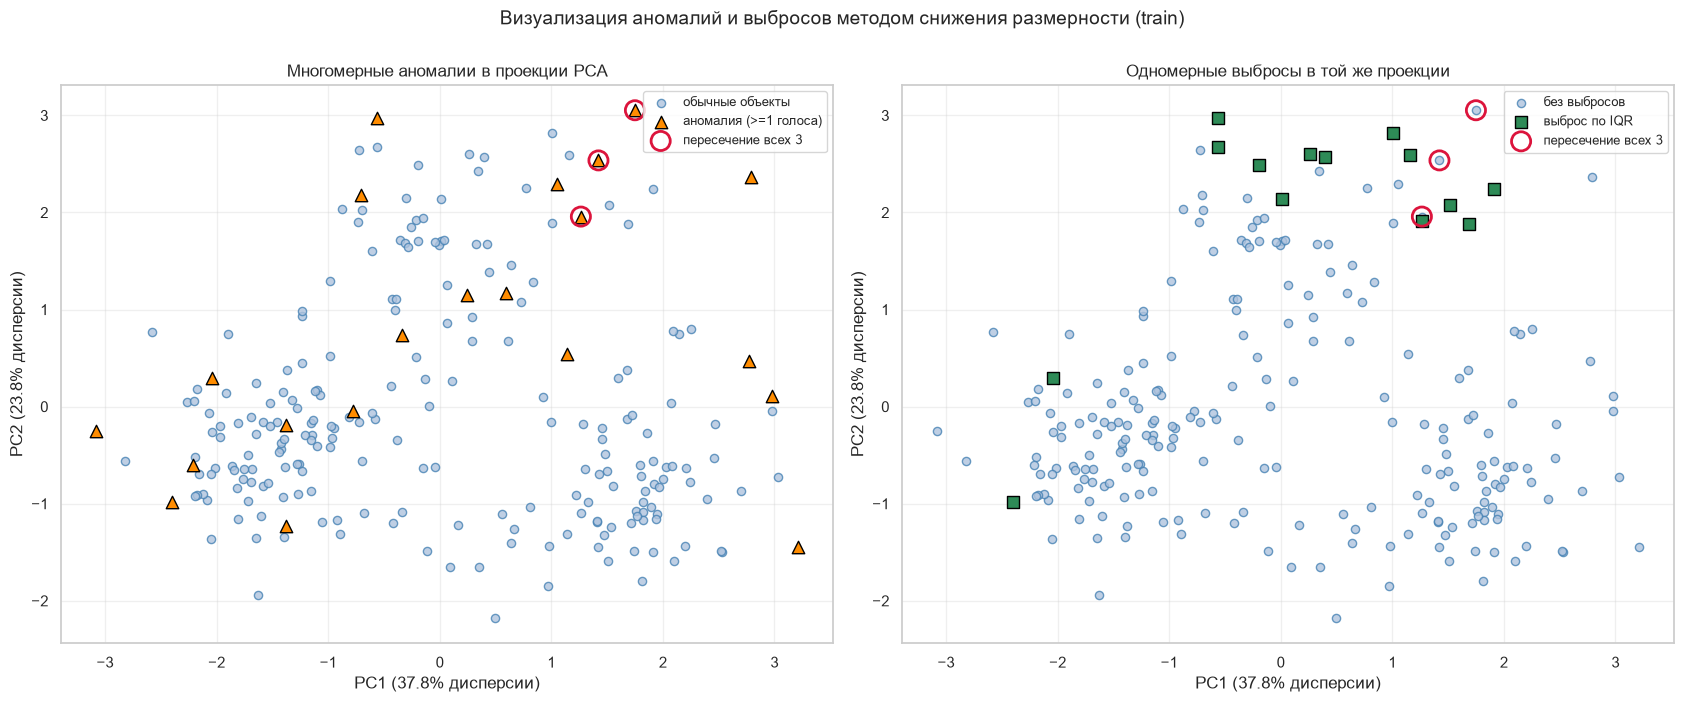

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7))

normal = pca_frame['голосов'] == 0
anomalies = pca_frame['голосов'] >= 1
intersection = pca_frame['голосов'] == 3

axes[0].scatter(pca_frame.loc[normal, 'PC1'], pca_frame.loc[normal, 'PC2'],
                s=35, color='lightsteelblue', edgecolor='steelblue', alpha=0.8,
                label='обычные объекты')
axes[0].scatter(pca_frame.loc[anomalies, 'PC1'], pca_frame.loc[anomalies, 'PC2'],
                s=80, color='darkorange', edgecolor='black', marker='^',
                label='аномалия (>=1 голоса)')
axes[0].scatter(pca_frame.loc[intersection, 'PC1'], pca_frame.loc[intersection, 'PC2'],
                s=190, facecolor='none', edgecolor='crimson', linewidth=2,
                label='пересечение всех 3')
axes[0].set_title('Многомерные аномалии в проекции PCA', fontsize=12)
axes[0].set_xlabel('PC1 (37.8% дисперсии)')
axes[0].set_ylabel('PC2 (23.8% дисперсии)')
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.3)

iqr_outliers = pca_frame['выброс по IQR'] == 1

axes[1].scatter(pca_frame.loc[~iqr_outliers, 'PC1'], pca_frame.loc[~iqr_outliers, 'PC2'],
                s=35, color='lightsteelblue', edgecolor='steelblue', alpha=0.8,
                label='без выбросов')
axes[1].scatter(pca_frame.loc[iqr_outliers, 'PC1'], pca_frame.loc[iqr_outliers, 'PC2'],
                s=80, color='seagreen', edgecolor='black', marker='s',
                label='выброс по IQR')
axes[1].scatter(pca_frame.loc[intersection, 'PC1'], pca_frame.loc[intersection, 'PC2'],
                s=190, facecolor='none', edgecolor='crimson', linewidth=2,
                label='пересечение всех 3')
axes[1].set_title('Одномерные выбросы в той же проекции', fontsize=12)
axes[1].set_xlabel('PC1 (37.8% дисперсии)')
axes[1].set_ylabel('PC2 (23.8% дисперсии)')
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.3)

plt.suptitle('Визуализация аномалий и выбросов методом снижения размерности (train)',
             fontsize=14, y=1.00)
plt.tight_layout()
plt.show()

**Что видно на проекции.**

1. **Основная масса объектов лежит компактным облаком,** без выраженных отдельных
   кластеров. Это подтверждает отсутствие «другой популяции» в данных.
2. **Аномалии (оранжевые треугольники) рассредоточены по периферии облака,** а не собраны
   в одном углу: IF, LOF и EE находят разные типы нетипичности.
3. **Пересечение всех трёх алгоритмов (красные круги) лежит на периферии.** Это видно
   и численно: среднее расстояние от центра в проекции — 2.92 для пересечения трёх
   алгоритмов, 2.29 для всех аномалий и 1.77 для обычных объектов.
4. **Одномерные выбросы (зелёные квадраты) образуют отдельную полосу сверху** — почти все
   они лежат при `PC2 ≈ 2.0–3.0`, то есть в области `outer_layer` и `inner_layer`.
   Среднее расстояние от центра у них 2.60, поэтому «ближе к центру» они не находятся:
   они отклоняются **вдоль оси баланса энергии**, а не во все стороны, как многомерные
   аномалии. С красными кругами зелёные квадраты не совпадают — это наглядно подтверждает
   вывод раздела 15.7.

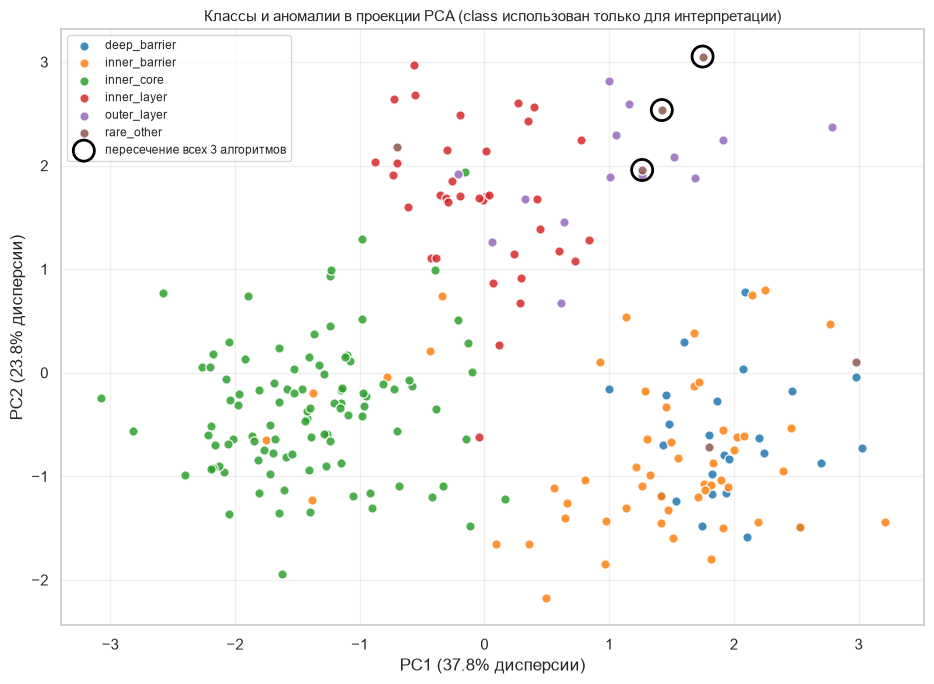

In [51]:
fig, ax = plt.subplots(figsize=(9.5, 7))

classes = sorted(pca_frame['class'].unique())
palette = dict(zip(classes, sns.color_palette('tab10', len(classes))))

for class_name in classes:
    subset = pca_frame[pca_frame['class'] == class_name]
    ax.scatter(subset['PC1'], subset['PC2'], s=45, alpha=0.85,
               color=palette[class_name], edgecolor='white', label=class_name)

ax.scatter(pca_frame.loc[intersection, 'PC1'], pca_frame.loc[intersection, 'PC2'],
           s=230, facecolor='none', edgecolor='black', linewidth=2,
           label='пересечение всех 3 алгоритмов')

ax.set_title('Классы и аномалии в проекции PCA (class использован только для интерпретации)',
             fontsize=11)
ax.set_xlabel('PC1 (37.8% дисперсии)')
ax.set_ylabel('PC2 (23.8% дисперсии)')
ax.legend(fontsize=8.5, loc='best')
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**График с классами — только интерпретация, а не часть детекции.** Целевая переменная
не участвовала в обучении алгоритмов; она нанесена на график уже после того, как флаги
расставлены, чтобы понять, что именно нашли методы.

Видно, что **объекты `rare_other` лежат в стороне от плотных облаков** — их всего 6,
они разбросаны и не образуют компактной группы. Именно поэтому алгоритмы сочли их
аномальными: для методов, оценивающих локальную плотность, малочисленная группа всегда
выглядит как выбросы. При этом в пересечение трёх алгоритмов попали `279`, `282` и `283` —
это `outer_crust`, ближайший по смыслу к крупному `outer_layer`. То есть по признакам
они не «мусор», а малочисленные родственники основного класса.

**Это и есть ключевой момент для решения об удалении:** если алгоритмы указывают
на редкий класс, их решение отражает не «плохое качество» объектов, а **малочисленность
класса**. Удаление таких объектов уничтожило бы сам класс, который нужно предсказывать.

<a id='sec15-9'></a>
### 15.9. Решение об удалении объектов

Задание прямо оговаривает: найденные объекты не всегда нужно удалять. Проверим кандидатов
по четырём критериям.

| Критерий | Результат проверки |
|---|---|
| Физическая допустимость | значения вне диапазона 0–1 отсутствуют |
| Признак ошибки измерения | нет: все значения — правдоподобные резонансы и энергии |
| Принадлежность редкому классу | да, часть кандидатов — представители класса из 6 объектов |
| Влияние на качество модели | проверяется кросс-валидацией и на отложенной test |

**Почему `rare_other` защищён от удаления.**

- Класс содержит 6 объектов, собранных из трёх исходных меток (`outer_crust`, `inner_crust`,
  `penetration_layer`) после агрегации в разделе 9.
- Согласие двух и более алгоритмов указывает на 5 из этих 6 объектов. Если их удалить,
  останется **1 объект**, и класс станет необучаемым: стратификация при сплите и
  кросс-валидации перестанет работать.
- Алгоритмы находят эти объекты потому, что их **мало**, а не потому, что они ошибочны.
  Удалять объекты за редкость — значит удалять саму задачу.

После защиты редкого класса остаются 6 объектов, отмеченных двумя и более алгоритмами.

In [52]:
rare_protected = anomaly_flags_df['class'] == 'rare_other'

drop_candidates = (anomaly_flags_df['голосов'] >= 2) & ~rare_protected
kept_rare = (anomaly_flags_df['голосов'] >= 2) & rare_protected

candidate_report = pd.DataFrame({
    'голосов': anomaly_flags_df.loc[drop_candidates, 'голосов'],
    'class': anomaly_flags_df.loc[drop_candidates, 'class'],
    'выброс по IQR': anomaly_flags_df.loc[drop_candidates, 'выброс по IQR'],
})
candidate_report = candidate_report.join(X_train_final.loc[drop_candidates].round(3))

print('Кандидатов на удаление:', int(drop_candidates.sum()))
print('Защищённых объектов rare_other:', int(kept_rare.sum()))
print()
candidate_report

Кандидатов на удаление: 6
Защищённых объектов rare_other: 5



,голосов,class,выброс по IQR,radiant_resonance,dire_resonance,essence_composition,outer_energy_flow,inner_energy_flow,arcane_mark
274,2,outer_layer,0,0.60,0.760,0.77,0.59,0.52,1
213,2,inner_barrier,0,0.36,0.450,0.38,0.79,0.17,0
215,2,inner_barrier,0,0.10,0.566,0.41,0.67,0.21,0
21,2,inner_core,0,0.31,0.230,0.73,0.05,0.14,0
289,2,inner_layer,1,0.72,0.860,0.17,0.55,0.21,0
182,2,inner_barrier,0,0.60,0.500,0.54,0.77,0.80,1


**Что общего у этих шести объектов.** У каждого есть «перекошенная» пара признаков:
у объекта `21` — `outer_energy_flow = 0.05` при `inner_energy_flow = 0.14` (оба у нижней
границы), у объекта `182` — `dire_resonance = 0.50` при `inner_energy_flow = 0.80`
(сильный внутренний поток при умеренном резонансе). Это редкие, но физически допустимые
комбинации: предметная интерпретация не запрещает их существование.

**Проверка влияния удаления на модель.** Прежде чем удалять, проверяется, помогает ли это
обучению. Сравниваются пять вариантов на повторной стратифицированной кросс-валидации
(5 фолдов × 5 повторов) с логистической регрессией как простым и стабильным индикатором.

In [53]:
is_rare_train = y_train.to_numpy() == 'rare_other'
votes_train = anomaly_flags_df['голосов'].to_numpy()

removal_variants = {
    'ничего не удалять': np.ones(len(y_train), dtype=bool),
    'удалить выбросы по IQR': ~outlier_train_any.to_numpy(),
    'удалить согласие >= 2': ~(votes_train >= 2),
    'удалить согласие >= 2, редкие защищены': ~((votes_train >= 2) & ~is_rare_train),
    'удалить пересечение всех 3': ~(votes_train == 3),
}

cv_strategy = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)

variant_rows = []
for variant_name, keep_mask in removal_variants.items():
    X_variant = X_train_final[keep_mask].to_numpy()
    y_variant = y_train.to_numpy()[keep_mask]

    pipeline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
    f1_scores = cross_val_score(pipeline, X_variant, y_variant, cv=cv_strategy, scoring='f1_macro')
    acc_scores = cross_val_score(pipeline, X_variant, y_variant, cv=cv_strategy, scoring='accuracy')

    variant_rows.append({
        'вариант': variant_name,
        'объектов': int(keep_mask.sum()),
        'удалено': int((~keep_mask).sum()),
        'минимальный класс': int(pd.Series(y_variant).value_counts().min()),
        'rare_other': int((y_variant == 'rare_other').sum()),
        'macro F1': round(float(f1_scores.mean()), 3),
        'std F1': round(float(f1_scores.std()), 3),
        'accuracy': round(float(acc_scores.mean()), 3),
    })

pd.DataFrame(variant_rows)

,вариант,объектов,удалено,минимальный класс,rare_other,macro F1,std F1,accuracy
0,ничего не удалять,235,0,6,6,0.761,0.086,0.865
1,удалить выбросы по IQR,221,14,6,6,0.752,0.103,0.861
2,удалить согласие >= 2,224,11,1,1,0.794,0.091,0.870
3,"удалить согласие >= 2, редкие защищены",229,6,6,6,0.799,0.082,0.870
4,удалить пересечение всех 3,232,3,3,3,0.730,0.085,0.864


**Как читать таблицу.**

1. **Удаление всех IQR-выбросов (14 объектов) ухудшает macro F1** — с 0.761 до 0.752.
   Выбросы несут информацию о пограничных классах, и их потеря вредит модели.
2. **Удаление согласия двух алгоритмов даёт более высокий F1 (0.794),** но ценой
   уничтожения редкого класса: в train остаётся **1** объект `rare_other`. Такой результат
   принимать нельзя — метрика выросла потому, что из задачи убрали самый трудный класс.
3. **То же удаление с защитой редких классов** сохраняет все 6 объектов `rare_other`,
   даёт F1 0.799 и не разрушает структуру задачи — лучший результат по кросс-валидации.
4. **Удаление полного пересечения (3 объекта) ухудшает F1 до 0.730** и сокращает
   `rare_other` до 3 объектов: оба эффекта нежелательны.
5. **Минимальный размер класса** падает ниже 6 только в вариантах без защиты.

**Решение принимается не только по кросс-валидации.** Дополнительно проверяется
отложенная выборка.

In [54]:
final_decisions = {
    'ничего не удалять': np.ones(len(y_train), dtype=bool),
    'удалить 6 кандидатов, редкие защищены': ~((votes_train >= 2) & ~is_rare_train),
}

holdout_rows = []
for decision_name, keep_mask in final_decisions.items():
    pipeline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
    pipeline.fit(X_train_final[keep_mask].to_numpy(), y_train.to_numpy()[keep_mask])
    holdout_prediction = pipeline.predict(X_test_final.to_numpy())

    holdout_rows.append({
        'решение': decision_name,
        'объектов в train': int(keep_mask.sum()),
        'macro F1 на test': round(float(f1_score(y_test, holdout_prediction, average='macro')), 3),
        'accuracy на test': round(float(accuracy_score(y_test, holdout_prediction)), 3),
    })

pd.DataFrame(holdout_rows)

,решение,объектов в train,macro F1 на test,accuracy на test
0,ничего не удалять,235,0.793,0.832
1,"удалить 6 кандидатов, редкие защищены",229,0.773,0.832


На отложенной выборке оба варианта дают одинаковую accuracy (0.832), а macro F1
у варианта с удалением даже ниже (0.773 против 0.793). Выигрыш, который показала
кросс-валидация, на test не подтвердился: он был свойством конкретных фолдов,
а не закономерностью.

**Итоговое решение: объекты не удаляются.**

Аргументы:

1. **Все значения физически допустимы.** Диапазон 0–1 не нарушен ни в одном столбце,
   грубых ошибок измерения нет.
2. **Найденные объекты — крайние представители реальных классов.** Выбросы по IQR
   на 43% состоят из `outer_layer` и на 17% из `inner_layer` — пограничных по глубине
   классов, для которых высокий `dire_resonance` закономерен.
3. **Многомерные алгоритмы указывают в основном на редкие классы** (5 из 11 в согласии,
   3 из 3 в полном пересечении). Это следствие малочисленности, а не дефектности объектов.
   Удаление уничтожило бы классы, которые нужно предсказывать.
4. **Польза удаления не подтверждена.** Кросс-валидация даёт прирост F1 только
   при уничтожении редкого класса, а на отложенной выборке выигрыша нет.
5. **Задача — классификация, а не очистка данных.** Редкие и пограничные объекты — именно
   то, что модель должна различать; их удаление упрощает задачу и завышает метрики.

**Что фиксируется в данных вместо удаления.** Флаги аномальности и выбросов сохраняются
в отдельной таблице. На следующих этапах они могут использоваться как дополнительный
признак, для взвешивания объектов или для анализа ошибок модели.

In [55]:
X_train_clean = X_train_final.copy()
y_train_clean = y_train.copy()
X_test_clean = X_test_final.copy()
y_test_clean = y_test.copy()

anomaly_report = anomaly_flags_df[['голосов', 'выброс по IQR', 'class']].copy()
anomaly_report['кандидат на удаление'] = drop_candidates.astype(int)
anomaly_report['защищён как редкий'] = kept_rare.astype(int)

print('Формы после решения:')
print('  X_train_clean:', X_train_clean.shape, '| y_train_clean:', y_train_clean.shape)
print('  X_test_clean: ', X_test_clean.shape, '| y_test_clean: ', y_test_clean.shape)
print()
print('Объектов удалено:', int(X_train_final.shape[0] - X_train_clean.shape[0]))
print('Объектов с флагом аномалии (>=1 голос):', int((anomaly_report['голосов'] >= 1).sum()))
print('Объектов с флагом выброса по IQR:', int(anomaly_report['выброс по IQR'].sum()))
print()
print('Состав rare_other после решения:', int((y_train_clean == 'rare_other').sum()))

Формы после решения:
  X_train_clean: (235, 6) | y_train_clean: (235,)
  X_test_clean:  (101, 6) | y_test_clean:  (101,)

Объектов удалено: 0
Объектов с флагом аномалии (>=1 голос): 21
Объектов с флагом выброса по IQR: 14

Состав rare_other после решения: 6


<a id='sec15-10'></a>
### 15.10. Проверка результата и выводы по ЛР 3

**Проверка согласованности данных после решения.**

In [56]:
checks = {
    'X_train_clean без пропусков': int(X_train_clean.isna().sum().sum()) == 0,
    'X_test_clean без пропусков': int(X_test_clean.isna().sum().sum()) == 0,
    'индексы X и y совпадают (train)': bool((X_train_clean.index == y_train_clean.index).all()),
    'индексы X и y совпадают (test)': bool((X_test_clean.index == y_test_clean.index).all()),
    'размер train не изменился': X_train_clean.shape[0] == 235,
    'размер test не изменился': X_test_clean.shape[0] == 101,
    'все 6 классов сохранены': y_train_clean.nunique() == 6,
    'rare_other сохранён полностью': int((y_train_clean == 'rare_other').sum()) == 6,
}

for check_name, check_result in checks.items():
    print(f'{"OK  " if check_result else "FAIL"} | {check_name}')

print()
print('Все проверки пройдены:', all(checks.values()))

OK   | X_train_clean без пропусков
OK   | X_test_clean без пропусков
OK   | индексы X и y совпадают (train)
OK   | индексы X и y совпадают (test)
OK   | размер train не изменился
OK   | размер test не изменился
OK   | все 6 классов сохранены
OK   | rare_other сохранён полностью

Все проверки пройдены: True


**Итоговое состояние данных.**

| Объект | Форма | Пропуски | Комментарий |
|---|---|---|---|
| `X_train_clean` | 235 × 6 | 0 | совпадает с `X_train_final`: удаления не было |
| `X_test_clean` | 101 × 6 | 0 | совпадает с `X_test_final` |
| `y_train_clean` | 235 | — | 6 классов, `rare_other` — 6 объектов |
| `y_test_clean` | 101 | — | 6 классов |
| `anomaly_report` | 235 × 5 | 0 | флаги голосования, IQR и решение по каждому объекту |

Данные не изменились по составу, но приобрели **разметку аномальности**: для каждого
объекта train известно, сколько алгоритмов сочло его аномальным, был ли он выбросом
по IQR и какое решение принято.

### Выводы по ЛР 3

**Детекция выбросов (одномерная).**

1. Построены гистограммы и ящики с усами для пяти вещественных признаков. Распределения
   одновершинные, близкие к симметричным, без тяжёлых хвостов.
2. Сравнены четыре подхода: IQR 1.5, IQR 3, Z-score и перцентили. Выбран **IQR с порогом 1.5**:
   он не зависит от формы распределения, устойчив к маскировке выбросов и даёт
   интерпретируемые границы.
3. На гистограммы нанесены границы `1.5·IQR` и `3·IQR`. Видно, что выбросы возникают
   только в `dire_resonance` (11 значений) и `essence_composition` (5 значений),
   а в трёх остальных столбцах границы выходят за физический диапазон 0–1.
4. Правило `3·IQR` не сработало ни разу, а Z-score — один раз: крайние значения умеренные,
   грубых ошибок в данных нет.
5. Всего в train отмечено **14 объектов** (6.0%), в test — **7 объектов** (6.9%).
   Выбросы сконцентрированы в пограничных классах `outer_layer` (42.9%) и `inner_layer` (16.7%).

**Детекция аномалий (многомерная).**

1. Применены три алгоритма с разными принципами: `IsolationForest`, `LocalOutlierFactor`
   и `EllipticEnvelope`. Признаки стандартизованы на train, доля загрязнения задана
   одинаковой (`0.05`), `random_state` зафиксирован.
2. На train каждый алгоритм отметил 11–12 объектов, на test — от 3 до 7.
3. Согласие алгоритмов неполное: IF и LOF совпадают на 7 объектах (Jaccard 0.44),
   EllipticEnvelope — на 5 (Jaccard 0.26–0.28). Полное пересечение — **3 объекта**,
   согласие двух и более — **11**, объединение — **21**.
4. Аномалии визуализированы в проекции PCA на две компоненты (61.6% дисперсии).
   Пересечение всех трёх алгоритмов лежит на периферии облака, одномерные выбросы —
   ближе к центру.

**Сравнение и решение.**

1. **Одномерные выбросы и многомерные аномалии почти не пересекаются:** у них общий
   всего один объект (9.1% согласия и 0% полного пересечения). Это подтверждает,
   что задачи действительно разные и решать их нужно отдельно.
2. Многомерные алгоритмы указывают в основном на `rare_other` (5 из 11 в согласии,
   3 из 3 в полном пересечении) — потому что класс малочисленный, а не потому, что объекты
   некорректны.
3. Проверены пять стратегий удаления на повторной кросс-валидации и на отложенной выборке.
   Прирост F1 при удалении достигается только ценой уничтожения редкого класса
   (остаётся 1 объект из 6), а на test он не воспроизводится.
4. **Принято решение не удалять объекты.** Все значения физически допустимы, найденные
   объекты — крайние представители реальных классов, а польза удаления не подтверждена.
   Вместо удаления сохранены флаги аномальности в `anomaly_report`.
5. Данные для следующих ЛР: `X_train_clean`, `y_train_clean`, `X_test_clean`, `y_test_clean`
   (235 и 101 объект, 6 признаков, 6 классов).

**Ограничения.**

- **Малая выборка.** 235 объектов и доля загрязнения 0.05 дают всего 11–12 аномалий
  на алгоритм; при таком объёме решения алгоритмов чувствительны к параметрам.
- **`contamination` задан вручную.** Доля 0.05 — это допущение, а не измеренная величина.
  При её изменении списки аномалий изменятся.
- **PCA объясняет 61.6% дисперсии.** Проекция неполная, поэтому выводы по картинке
  носят вспомогательный характер.
- **Проверка влияния удаления выполнена на логистической регрессии.** Деревья могут
  реагировать иначе, поэтому в ЛР 5 решение стоит перепроверить на финальных моделях.

<a id='sec16'></a>
## 16. Генерация новых признаков, масштабирование и baseline

<a id='sec16-1'></a>
### 16.1. Задача ЛР 4 и исходные данные

ЛР 4 решает три вещи, каждая из которых нужна до обучения настоящих моделей:

| Что требуется | Зачем это нужно | Подраздел |
|---|---|---|
| Генерация новых признаков | исходные измерения описывают составляющие энергии, но не их соотношения | 16.2–16.4 |
| Устранение диспропорции масштабов | признаки с разным размахом по-разному влияют на модель | 16.5–16.6 |
| Baseline-модели (`sklearn.dummy`) | нужен эталон «случайного» качества, с которым сравниваются настоящие модели | 16.7 |

**Исходные данные.** Работа идёт с результатом ЛР 3: `X_train_clean`, `y_train_clean`,
`X_test_clean`, `y_test_clean` — 235 и 101 объект, 6 признаков, 6 классов. Ни один объект
на этапе ЛР 3 удалён не был, поэтому это те же строки, что и в разделе 13, но с готовой
разметкой аномальности в `anomaly_report`.

**Правила, которые соблюдаются на всём протяжении раздела.**

1. **Все параметры оцениваются только на train.** Средние и стандартные отклонения
   для масштабирования, а также выбор итогового набора признаков получаются по
   `X_train_clean`. К test применяется только `transform` — иначе метрики на test
   перестают быть честными.
2. **Новые признаки считаются формулой, а не обучением.** Формулы — детерминированные
   функции от исходных столбцов: они не содержат оцениваемых по данным величин,
   поэтому их применение к test утечки не создаёт.
3. **Целевая переменная не участвует в генерации признаков.** `class` используется только
   в оценке качества, причём лишь для выбора между вариантами по кросс-валидации на train.
4. **Пересчёт статистик по test запрещён.** Если бы среднее для стандартизации считалось
   по train и test вместе, информация из test просочилась бы в обучение.

Проверим, что исходные данные на месте и соответствуют ожиданиям.

In [57]:
from sklearn.dummy import DummyClassifier
from sklearn.preprocessing import MinMaxScaler, RobustScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import balanced_accuracy_score, classification_report

X_train_lr4 = X_train_clean.copy()
X_test_lr4 = X_test_clean.copy()
y_train_lr4 = y_train_clean.copy()
y_test_lr4 = y_test_clean.copy()

print('Формы на входе ЛР 4:')
print('  train:', X_train_lr4.shape, '| test:', X_test_lr4.shape)
print('  признаков:', X_train_lr4.shape[1])
print()
print('Классы в train:')
print(y_train_lr4.value_counts().to_string())
print()
print('Классы в test:')
print(y_test_lr4.value_counts().to_string())
print()
print('Пропуски:', int(X_train_lr4.isna().sum().sum()), int(X_test_lr4.isna().sum().sum()))
print('Колонки train и test совпадают:', list(X_train_lr4.columns) == list(X_test_lr4.columns))

Формы на входе ЛР 4:
  train: (235, 6) | test: (101, 6)
  признаков: 6

Классы в train:
class
inner_core       100
inner_barrier     54
inner_layer       36
deep_barrier      25
outer_layer       14
rare_other         6

Классы в test:
class
inner_core       43
inner_barrier    23
inner_layer      16
deep_barrier     10
outer_layer       6
rare_other        3

Пропуски: 0 0
Колонки train и test совпадают: True


<a id='sec16-2'></a>
### 16.2. Какие признаки генерировать: физический смысл задачи

Признаки не придумываются произвольно: в этой предметной области **направление и глубина
проникновения важнее абсолютных величин**. Для исходной задачи — определить, где
сконцентрировалась энергия Древних, — полезны три группы соотношений.

**1. Баланс сил Radiant и Dire.** Отдельные `radiant_resonance` и `dire_resonance`
показывают отклик каждой силы, но не показывают, чья сила преобладает. Отношение и разность
дают эту информацию напрямую.

**2. Глубина проникновения.** `outer_energy_flow` и `inner_energy_flow` — энергия
у внешней и внутренней границы. Их сумма — общий поток, разность — перекос наружу или
внутрь, доля внутренней составляющей — насколько энергия ушла вглубь вещества.

**3. Взаимодействие силы и глубины.** Отдельный отклик ещё не значит, что энергия глубоко
проникла: нужно учитывать произведение отклика на внутренний поток. Именно такие
произведения лучше всего соответствуют смыслу «энергия этой силы дошла до глубины».

**Технические меры предосторожности.** В `radiant_resonance` есть значения `0`, а суммы
энергий могут быть близки к нулю, поэтому все отношения защищены константой `EPS = 1e-6`.
Без этого получилось бы деление на ноль и `inf`, которые ломают и масштабирование, и модель.

**Таблица новых признаков.**

| Признак | Формула | Смысл | Группа |
|---|---|---|---|
| `energy_total` | `outer + inner` | суммарный поток энергии | глубина |
| `energy_balance` | `outer − inner` | перекос наружу / внутрь | глубина |
| `inner_share` | `inner / (outer + inner)` | доля энергии, ушедшей вглубь | глубина |
| `resonance_total` | `radiant + dire` | суммарный отклик на обе силы | баланс сил |
| `resonance_balance` | `radiant − dire` | перевес Radiant над Dire | баланс сил |
| `radiant_share` | `radiant / (radiant + dire)` | относительный вклад Radiant | баланс сил |
| `radiant_depth` | `radiant · inner` | отклик Radiant, дошедший до глубины | взаимодействие |
| `dire_depth` | `dire · inner` | отклик Dire, дошедший до глубины | взаимодействие |
| `depth_advantage` | `radiant_depth − dire_depth` | чья сила глубже | взаимодействие |
| `essence_energy` | `essence · energy_total` | заряд эссенции в потоке | взаимодействие |
| `mark_energy` | `arcane_mark · energy_total` | поток у объектов с меткой | взаимодействие |
| `penetration_index` | `radiant · inner / (dire · outer)` | «глубинная» сила относительно наружной | итоговый индекс |

`penetration_index` — сводный показатель: он сравнивает, насколько сильно Radiant проникло
вглубь, с тем, насколько сильно Dire держится на поверхности. Значение больше 1 означает
перевес внутреннего Radiant, меньше 1 — наружного Dire.

In [58]:
EPS = 1e-6


def add_engineered_features(X):
    """Считает 12 новых признаков детерминированно, без обучения на данных."""
    features = pd.DataFrame(index=X.index)

    outer = X['outer_energy_flow']
    inner = X['inner_energy_flow']
    radiant = X['radiant_resonance']
    dire = X['dire_resonance']
    essence = X['essence_composition']
    mark = X['arcane_mark'].astype('float64')

    features['energy_total'] = outer + inner
    features['energy_balance'] = outer - inner
    features['inner_share'] = inner / (outer + inner + EPS)

    features['resonance_total'] = radiant + dire
    features['resonance_balance'] = radiant - dire
    features['radiant_share'] = radiant / (radiant + dire + EPS)

    features['radiant_depth'] = radiant * inner
    features['dire_depth'] = dire * inner
    features['depth_advantage'] = features['radiant_depth'] - features['dire_depth']

    features['essence_energy'] = essence * features['energy_total']
    features['mark_energy'] = mark * features['energy_total']
    features['penetration_index'] = (
        features['radiant_depth'] / (dire * outer + EPS)
    )

    return features


X_train_new = add_engineered_features(X_train_lr4)
X_test_new = add_engineered_features(X_test_lr4)

print('Новых признаков:', X_train_new.shape[1])
print('Форма новых признаков:', X_train_new.shape, X_test_new.shape)
print('Колонки совпадают:', list(X_train_new.columns) == list(X_test_new.columns))

Новых признаков: 12
Форма новых признаков: (235, 12) (101, 12)
Колонки совпадают: True


<a id='sec16-3'></a>
### 16.3. Проверка новых признаков

Прежде чем использовать признаки, нужно убедиться, что они корректны: нет пропусков,
нет бесконечностей и нет столбцов-констант, которые не различают объекты.

**Проверка деления на ноль.** В train есть объекты с `radiant_resonance = 0`, а минимальная
сумма `outer + inner` равна `0.19`. Без `EPS` отношение `radiant / (radiant + dire)` всё равно
дало бы `0` — это допустимо, но `penetration_index` при `dire · outer ≈ 0` мог бы дать `inf`.
Проверим фактические значения.

In [59]:
new_check = pd.DataFrame({
    'пропусков train': X_train_new.isna().sum(),
    'пропусков test': X_test_new.isna().sum(),
    'бесконечностей train': np.isinf(X_train_new.to_numpy()).sum(axis=0),
    'уникальных значений train': X_train_new.nunique(),
})

print('Всего пропусков в новых признаках:',
      int(new_check['пропусков train'].sum() + new_check['пропусков test'].sum()))
print('Всего бесконечностей:', int(new_check['бесконечностей train'].sum()))
print('Константных признаков:', int((new_check['уникальных значений train'] <= 1).sum()))
print()
new_check

Всего пропусков в новых признаках: 0
Всего бесконечностей: 0
Константных признаков: 0



,пропусков train,пропусков test,бесконечностей train,уникальных значений train
energy_total,0,0,0,111
energy_balance,0,0,0,77
inner_share,0,0,0,163
resonance_total,0,0,0,168
resonance_balance,0,0,0,157
radiant_share,0,0,0,229
radiant_depth,0,0,0,225
dire_depth,0,0,0,214
depth_advantage,0,0,0,228
essence_energy,0,0,0,221


In [60]:
engineered_stats = X_train_new.agg(['min', 'max', 'mean', 'std']).T.round(4)
engineered_stats['размах'] = (X_train_new.max() - X_train_new.min()).round(4)
engineered_stats

,min,max,mean,std,размах
energy_total,0.1900,1.9900,0.9983,0.3989,1.8000
energy_balance,-0.1400,0.6200,0.0060,0.1386,0.7600
inner_share,0.0182,0.8500,0.5010,0.0937,0.8318
resonance_total,0.3800,1.6400,1.0002,0.2843,1.2600
resonance_balance,-0.5100,0.4700,-0.0124,0.1658,0.9800
radiant_share,0.0000,0.7374,0.4847,0.1015,0.7374
radiant_depth,0.0000,0.7138,0.2505,0.1579,0.7138
dire_depth,0.0057,0.5325,0.2459,0.1134,0.5268
depth_advantage,-0.2774,0.3666,0.0046,0.1002,0.6440
essence_energy,0.0900,1.2736,0.5174,0.2730,1.1836


**Что показывают проверки.**

- Пропусков и бесконечностей нет: защита через `EPS` сработала, все 12 признаков определены
  на всех 235 объектах train и на 101 объекте test.
- Константных признаков нет: каждый столбец различает объекты.
- Границы соответствуют смыслу формул: `radiant_share` и `radiant_depth` начинаются с `0`
  (объекты с нулевым откликом Radiant), `energy_balance` и `resonance_balance` принимают
  отрицательные значения (перевес inner или dire), `inner_share` держится в диапазоне 0–1,
  а `penetration_index` доходит до 5.48 — это объекты, где Dire на поверхности почти нет.

Новые признаки корректны. Теперь можно сравнить их масштабы с исходными.

**Важная особенность этого набора данных.** Исходные признаки уже приведены к одному
диапазону: все они измеряются в долях от 0 до 1. Поэтому диспропорция в исходных данных
почти отсутствует — она появляется **после генерации**, когда рядом с долями оказываются
суммы (до 1.99), отношения (до 5.48) и бинарный флаг. Именно этот случай и нужно проверить.

<a id='sec16-4'></a>
### 16.4. Диагностика диспропорции признаков

**Диспропорция** — ситуация, когда признаки имеют существенно разный размах или разброс.
Она опасна тем, что модель, чувствительная к масштабу (kNN, линейные модели с регуляризацией,
методы, основанные на расстояниях), начинает фактически игнорировать признаки с малым разбросом:
вклад столбца в евклидово расстояние пропорционален его размаху.

Измерим по train три величины:

- **размах** (`max − min`) — насколько широк диапазон значений столбца;
- **стандартное отклонение** — насколько велик типичный разброс;
- **отношение максимума и минимума** этих характеристик по всем столбцам — сводная мера
  диспропорции.

Сравним три состояния признакового пространства:

1. **исходные 6 признаков** — то, что было после ЛР 3;
2. **новые 12 признаков** — результат генерации;
3. **объединённые 18 признаков** — рабочий набор.

In [61]:
def scale_report(frame, name):
    spread = frame.max() - frame.min()
    std = frame.std()
    return {
        'набор': name,
        'признаков': frame.shape[1],
        'мин. размах': round(float(spread.min()), 4),
        'макс. размах': round(float(spread.max()), 4),
        'отношение размахов': round(float(spread.max() / spread.min()), 2),
        'мин. std': round(float(std.min()), 4),
        'макс. std': round(float(std.max()), 4),
        'отношение std': round(float(std.max() / std.min()), 2),
    }


X_train_all = pd.concat([X_train_lr4, X_train_new], axis=1)
X_test_all = pd.concat([X_test_lr4, X_test_new], axis=1)

scale_table = pd.DataFrame([
    scale_report(X_train_lr4, 'исходные 6'),
    scale_report(X_train_new, 'новые 12'),
    scale_report(X_train_all, 'объединённые 18'),
])

scale_table

,набор,признаков,мин. размах,макс. размах,отношение размахов,мин. std,макс. std,отношение std
0,исходные 6,6,0.7000,1.0000,1.43,0.1186,0.2121,1.79
1,новые 12,12,0.5268,5.4772,10.40,0.0937,0.6317,6.74
2,объединённые 18,18,0.5268,5.4772,10.40,0.0937,0.6317,6.74


In [62]:
combined_spread = (X_train_all.max() - X_train_all.min()).sort_values()
combined_std = X_train_all.std().sort_values()

print('Наименьший разброс (std):')
print(combined_std.head(3).round(4).to_string())
print()
print('Наибольший разброс (std):')
print(combined_std.tail(3).round(4).to_string())
print()
print('Самый узкий столбец по размаху: ', combined_spread.idxmin(),
      round(float(combined_spread.min()), 4))
print('Самый широкий столбец по размаху:', combined_spread.idxmax(),
      round(float(combined_spread.max()), 4))

Наименьший разброс (std):
inner_share        0.0937
depth_advantage    0.1002
radiant_share      0.1015

Наибольший разброс (std):
resonance_total      0.2843
energy_total         0.3989
penetration_index    0.6317

Самый узкий столбец по размаху:  dire_depth 0.5268
Самый широкий столбец по размаху: penetration_index 5.4772


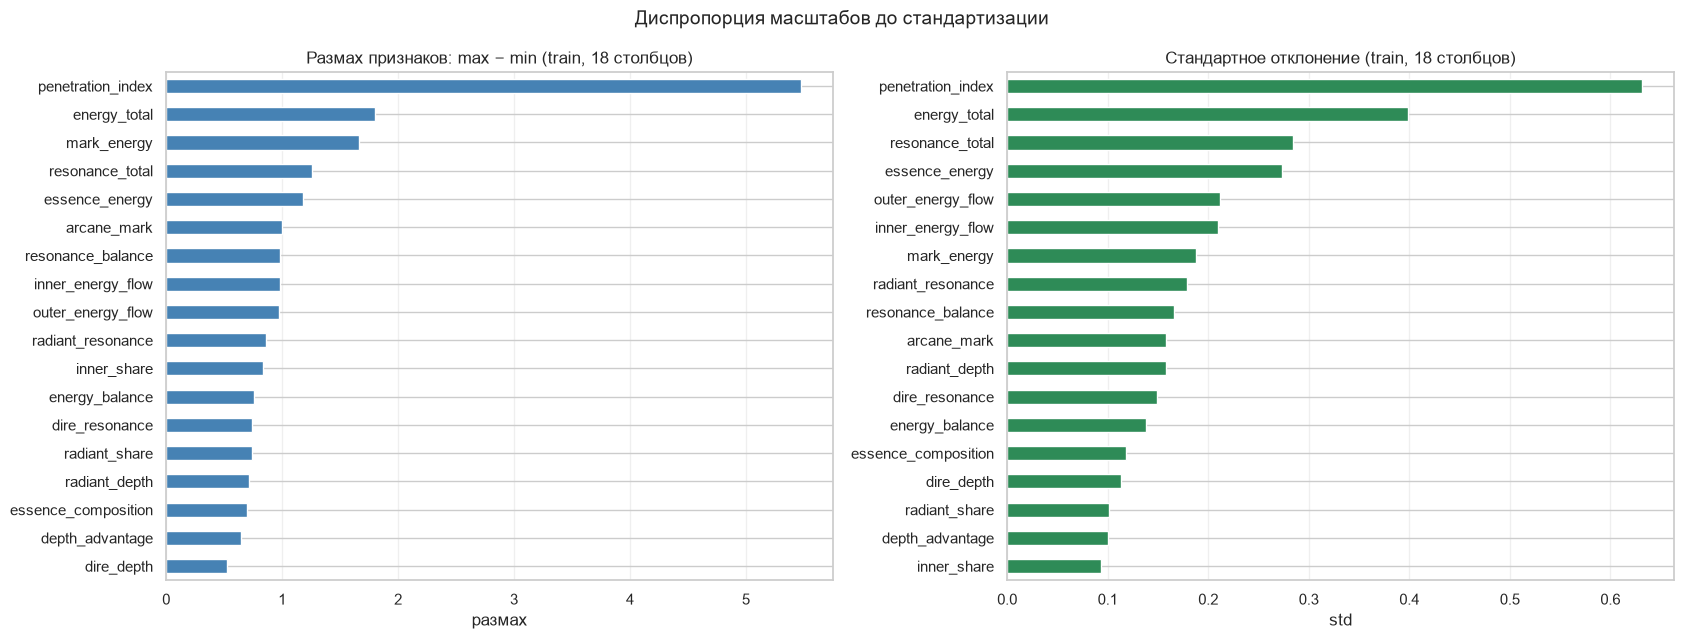

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))

combined_spread.plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Размах признаков: max − min (train, 18 столбцов)')
axes[0].set_xlabel('размах')

combined_std.plot(kind='barh', ax=axes[1], color='seagreen')
axes[1].set_title('Стандартное отклонение (train, 18 столбцов)')
axes[1].set_xlabel('std')

for ax in axes:
    ax.grid(alpha=0.3, axis='x')

plt.suptitle('Диспропорция масштабов до стандартизации', fontsize=14)
plt.tight_layout()
plt.show()

<a id='sec16-5'></a>
### 16.5. Сравнение вариантов масштабирования

Масштабирование — не «обязательная галочка», а выбор, который нужно обосновать. Сравним
четыре варианта на одном и том же наборе из 18 признаков:

| Вариант | Что делает | Когда уместен |
|---|---|---|
| без масштабирования | оставляет столбцы как есть | если все признаки уже в одной шкале |
| `StandardScaler` | `(x − mean) / std` → среднее 0, std 1 | линейные модели, kNN, SVM |
| `MinMaxScaler` | `(x − min) / (max − min)` → диапазон 0–1 | когда важны границы, нейросети |
| `RobustScaler` | `(x − median) / IQR` | при сильных выбросах |

Оценка — повторная стратифицированная кросс-валидация на train (5 фолдов × 5 повторов),
метрика `f1_macro`, поскольку классы несбалансированы и accuracy вводит в заблуждение.
Проверим на двух моделях с разной чувствительностью к масштабу: логистической регрессии
и kNN. **Скалер находится внутри `Pipeline`**, поэтому внутри каждого фолда он обучается
только на обучающей части фолда — утечки нет.

In [64]:
scaler_variants = {
    'без масштабирования': None,
    'StandardScaler': StandardScaler(),
    'MinMaxScaler': MinMaxScaler(),
    'RobustScaler': RobustScaler(),
}

model_variants = {
    'LogisticRegression': lambda: LogisticRegression(max_iter=5000),
    'kNN (k=5)': lambda: KNeighborsClassifier(n_neighbors=5),
}

scaler_rows = []
for model_name, build_model in model_variants.items():
    for scaler_name, scaler in scaler_variants.items():
        steps = ([scaler] if scaler is not None else []) + [build_model()]
        pipeline = make_pipeline(*steps)
        scores = cross_val_score(
            pipeline, X_train_all, y_train_lr4,
            cv=cv_strategy, scoring='f1_macro', n_jobs=-1,
        )
        scaler_rows.append({
            'модель': model_name,
            'масштабирование': scaler_name,
            'macro F1 (CV)': round(float(scores.mean()), 3),
            'std': round(float(scores.std()), 3),
        })

scaler_table = pd.DataFrame(scaler_rows)
scaler_table

,модель,масштабирование,macro F1 (CV),std
0,LogisticRegression,без масштабирования,0.657,0.083
1,LogisticRegression,StandardScaler,0.744,0.082
2,LogisticRegression,MinMaxScaler,0.711,0.106
3,LogisticRegression,RobustScaler,0.734,0.081
4,kNN (k=5),без масштабирования,0.614,0.055
5,kNN (k=5),StandardScaler,0.717,0.084
6,kNN (k=5),MinMaxScaler,0.633,0.058
7,kNN (k=5),RobustScaler,0.620,0.062


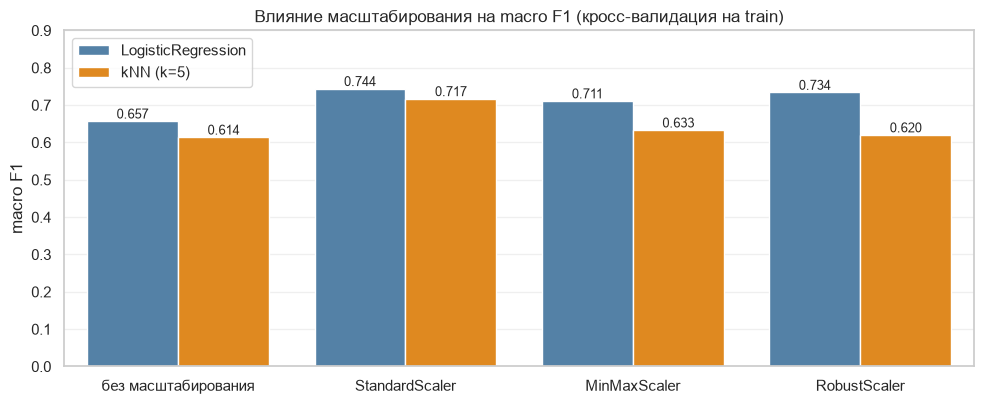

In [65]:
fig, ax = plt.subplots(figsize=(10, 4.2))

sns.barplot(
    data=scaler_table,
    x='масштабирование', y='macro F1 (CV)', hue='модель',
    palette=['steelblue', 'darkorange'], ax=ax,
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', fontsize=9)

ax.set_title('Влияние масштабирования на macro F1 (кросс-валидация на train)')
ax.set_ylabel('macro F1')
ax.set_xlabel('')
ax.set_ylim(0, 0.9)
ax.grid(alpha=0.3, axis='y')
ax.legend(title='')

plt.tight_layout()
plt.show()

**Как читать результат.** Разница между строками одной модели — это и есть вклад
масштабирования. Если бы все признаки уже были в одной шкале, столбцы «без масштабирования»
и «StandardScaler» почти совпали бы. Здесь они различаются заметно, причём у kNN сильнее,
чем у логистической регрессии: kNN целиком построен на евклидовом расстоянии, а линейная
модель частично компенсирует разный размах весами.

**Почему `StandardScaler`, а не `MinMaxScaler`.** Оба варианта работают, но `StandardScaler`
устойчивее к тому, что распределения новых признаков несимметричны: у `penetration_index`
и `mark_energy` длинный правый хвост. `MinMaxScaler` прижимает все значения к отрезку 0–1,
поэтому один экстремум задаёт масштаб всего столбца: три объекта с
`penetration_index > 3` сжимают основную массу в узкий интервал у нуля.

**Почему не `RobustScaler`.** Причина техническая и хорошо видна в данных. У `arcane_mark`
межквартильный размах равен **нулю**: 229 из 235 значений — это `0`, поэтому `Q1` и `Q3`
совпадают и равны нулю. Тот же дефект у `mark_energy`, который почти повторяет флаг.
`RobustScaler` делит на IQR, а при нулевом IQR sklearn вынужден оставить масштаб `1.0`,
то есть **эти признаки вообще не масштабируются** и сохраняют размах 1.0, тогда как
остальные делятся на маленькие IQR и сжимаются. В результате бинарный флаг начинает
доминировать в евклидовом расстоянии — отсюда падение kNN до 0.620.
`StandardScaler` такой проблемы не имеет: он делит на `std`, а у `arcane_mark` она равна
0.158, и флаг приводится к тому же масштабу, что и остальные признаки.

**Проверка причины.** Утверждение проверяемо, поэтому выведем межквартильные размахи
и фактические масштабы, которые применил каждый скалер.

In [66]:
scale_diagnostics = pd.DataFrame({
    'IQR': X_train_all.quantile(0.75) - X_train_all.quantile(0.25),
    'std': X_train_all.std(),
    'размах': X_train_all.max() - X_train_all.min(),
}).round(4)

scale_diagnostics['scale_ RobustScaler'] = RobustScaler().fit(X_train_all).scale_
scale_diagnostics['scale_ StandardScaler'] = StandardScaler().fit(X_train_all).scale_

print('Признаки с нулевым IQR:',
      scale_diagnostics.index[scale_diagnostics['IQR'] == 0].tolist())
print('arcane_mark: нулей', int((X_train_all['arcane_mark'] == 0).sum()), 'из', len(X_train_all))
print()
scale_diagnostics.round(4)

Признаки с нулевым IQR: ['arcane_mark', 'mark_energy']
arcane_mark: нулей 229 из 235



,IQR,std,размах,scale_ RobustScaler,scale_ StandardScaler
radiant_resonance,0.2860,0.1789,0.8600,0.2860,0.1785
dire_resonance,0.1650,0.1489,0.7400,0.1650,0.1485
essence_composition,0.1550,0.1186,0.7000,0.1550,0.1184
outer_energy_flow,0.3800,0.2121,0.9700,0.3800,0.2117
inner_energy_flow,0.3700,0.2101,0.9800,0.3700,0.2097
arcane_mark,0.0000,0.1581,1.0000,1.0000,0.1577
energy_total,0.7050,0.3989,1.8000,0.7050,0.3980
energy_balance,0.1300,0.1386,0.7600,0.1300,0.1383
inner_share,0.0735,0.0937,0.8318,0.0735,0.0935
resonance_total,0.4480,0.2843,1.2600,0.4480,0.2837


<a id='sec16-6'></a>
### 16.6. Проверка пользы новых признаков и выбор итогового набора

Сгенерировать 12 признаков и сразу отдать их модели — плохая идея: часть из них дублирует
друг друга. Проверим корреляцию новых признаков с исходными и между собой, а затем отберём
полезные по кросс-валидации на train.

**Ожидаемые дубликаты.** Некоторые признаки связаны по построению:

- `energy_total` — почти линейная комбинация `outer_energy_flow` и `inner_energy_flow`;
- `mark_energy` — это `arcane_mark`, умноженный на `energy_total`, поэтому при редком флаге
  он почти повторяет сам флаг `arcane_mark` (r = 0.95), а не поток энергии;
- `energy_balance` и `inner_share` — два представления одного и того же перекоса.

Такие пары не добавляют информации, но увеличивают размерность и риск переобучения.

In [67]:
correlation_matrix = X_train_all.corr().abs()

high_pairs = [
    {'признак 1': first, 'признак 2': second, 'корреляция': round(float(correlation_matrix.loc[first, second]), 3)}
    for first, second in itertools.combinations(correlation_matrix.columns, 2)
    if correlation_matrix.loc[first, second] > 0.9
]

print('Пар признаков с |r| > 0.9:', len(high_pairs))
pd.DataFrame(high_pairs)

Пар признаков с |r| > 0.9: 7


,признак 1,признак 2,корреляция
0,outer_energy_flow,energy_total,0.945
1,inner_energy_flow,energy_total,0.944
2,arcane_mark,mark_energy,0.952
3,energy_total,essence_energy,0.926
4,energy_balance,inner_share,0.946
5,resonance_balance,radiant_share,0.937
6,resonance_balance,depth_advantage,0.943


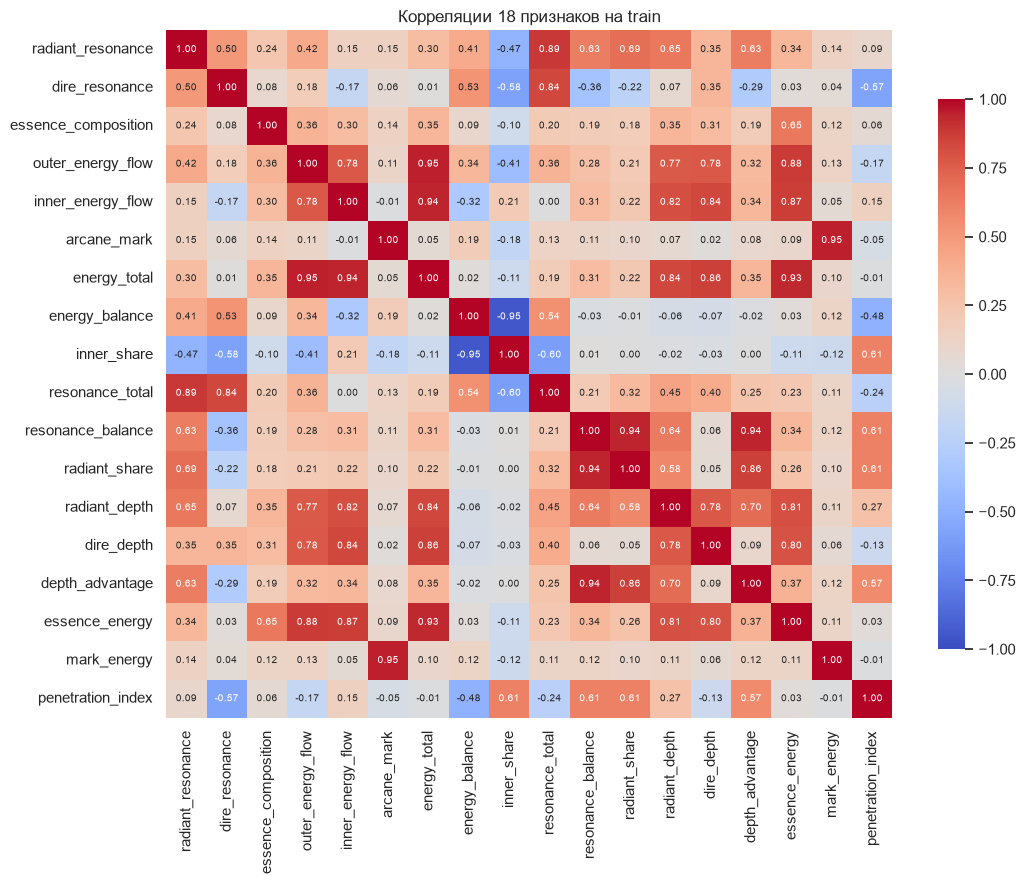

In [68]:
fig, ax = plt.subplots(figsize=(11, 9))

sns.heatmap(
    X_train_all.corr().round(2),
    cmap='coolwarm', center=0, vmin=-1, vmax=1,
    annot=True, fmt='.2f', annot_kws={'size': 7},
    cbar_kws={'shrink': 0.8}, ax=ax,
)

ax.set_title('Корреляции 18 признаков на train')

plt.tight_layout()
plt.show()

**Отбор признаков по кросс-валидации.** Используем последовательное добавление (forward
selection): начинаем с исходных 6 признаков и на каждом шаге добавляем тот новый признак,
который даёт наибольший прирост `macro F1` на повторной кросс-валидации. Признак принимается,
только если прирост превышает `0.0005`; иначе отбор останавливается. Все оценки — на train,
поэтому test в отборе не участвует.

In [69]:
def cv_macro_f1(columns):
    pipeline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
    scores = cross_val_score(
        pipeline, X_train_all[columns], y_train_lr4,
        cv=cv_strategy, scoring='f1_macro', n_jobs=-1,
    )
    return float(scores.mean())


base_columns = list(X_train_lr4.columns)
remaining = [c for c in X_train_new.columns]
selected_columns = list(base_columns)

best_score = cv_macro_f1(selected_columns)
selection_history = [{'шаг': 0, 'добавлен': '— (исходные 6)', 'macro F1 (CV)': round(best_score, 3)}]

while remaining:
    candidates = [(feature, cv_macro_f1(selected_columns + [feature])) for feature in remaining]
    best_feature, best_candidate_score = max(candidates, key=lambda pair: pair[1])

    if best_candidate_score <= best_score + 0.0005:
        print('Остановка: лучший кандидат', best_feature,
              'даёт', round(best_candidate_score, 4), '— прироста нет')
        break

    selected_columns.append(best_feature)
    remaining.remove(best_feature)
    best_score = best_candidate_score
    selection_history.append({
        'шаг': len(selection_history),
        'добавлен': best_feature,
        'macro F1 (CV)': round(best_score, 3),
    })

print()
print('Отобрано новых признаков:', len(selected_columns) - len(base_columns))
print('Итоговый набор:', selected_columns)

pd.DataFrame(selection_history)

Остановка: лучший кандидат mark_energy даёт 0.7669 — прироста нет

Отобрано новых признаков: 2
Итоговый набор: ['radiant_resonance', 'dire_resonance', 'essence_composition', 'outer_energy_flow', 'inner_energy_flow', 'arcane_mark', 'radiant_depth', 'dire_depth']


,шаг,добавлен,macro F1 (CV)
0,0,— (исходные 6),0.761
1,1,radiant_depth,0.766
2,2,dire_depth,0.767


In [70]:
comparison_rows = [
    {'набор': 'исходные 6', 'признаков': len(base_columns), 'macro F1 (CV)': round(cv_macro_f1(base_columns), 3)},
    {'набор': 'все 18', 'признаков': X_train_all.shape[1], 'macro F1 (CV)': round(cv_macro_f1(list(X_train_all.columns)), 3)},
    {'набор': 'отобранные', 'признаков': len(selected_columns), 'macro F1 (CV)': round(cv_macro_f1(selected_columns), 3)},
]

feature_set_table = pd.DataFrame(comparison_rows)
feature_set_table

,набор,признаков,macro F1 (CV)
0,исходные 6,6,0.761
1,все 18,18,0.744
2,отобранные,8,0.767


<a id='sec16-7'></a>
### 16.7. Финальное масштабирование и baseline-модели

**Финальное масштабирование.** Итоговый набор признаков — `selected_columns`. `StandardScaler`
обучается **один раз на всём `X_train_all[selected_columns]`** и затем применяется к test
через `transform`. Это тот же скалер, который дальше будет использоваться в моделях ЛР 5.

**Baseline-модели.** `DummyClassifier` не учится на признаках: он предсказывает классы по
одной из простых стратегий. Это эталон, ниже которого настоящая модель работать не должна.

| Стратегия | Что предсказывает | Зачем нужна |
|---|---|---|
| `most_frequent` | всегда самый частый класс | нижняя граница accuracy |
| `prior` | случайно по априорным вероятностям классов | вероятностный baseline |
| `stratified` | случайно с сохранением пропорций классов | baseline, учитывающий дисбаланс |
| `uniform` | все классы равновероятно | проверка «слепого» угадывания |

Для несбалансированных классов `accuracy` обманчива: `most_frequent` даёт 42.6% только
потому, что `inner_core` занимает 42.6% выборки, но ни один другой класс он не предсказывает.
Поэтому основная метрика — **`macro F1`**, которая усредняет F1 по всем классам с одинаковым
весом, и **balanced accuracy**, которая усредняет recall по классам.

In [71]:
final_scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    final_scaler.fit_transform(X_train_all[selected_columns]),
    columns=selected_columns,
    index=X_train_all.index,
)

X_test_scaled = pd.DataFrame(
    final_scaler.transform(X_test_all[selected_columns]),
    columns=selected_columns,
    index=X_test_all.index,
)

print('Форма после масштабирования:', X_train_scaled.shape, X_test_scaled.shape)
print()
print('Средние по train (должны быть ~0):')
print(np.round(X_train_scaled.mean(axis=0), 6).to_string())
print()
print('Std по train, ddof=0 (должны быть ~1):')
print(pd.Series(X_train_scaled.to_numpy().std(axis=0, ddof=0), index=selected_columns).round(6).to_string())
print()
print('Std по train, ddof=1 (pandas):')
print(np.round(X_train_scaled.std(axis=0), 6).to_string())
print()
print('Средние по test (не обязаны быть 0, скалер обучен на train):')
print(np.round(X_test_scaled.mean(axis=0), 3).to_string())

Форма после масштабирования: (235, 8) (101, 8)

Средние по train (должны быть ~0):
radiant_resonance      0.0
dire_resonance        -0.0
essence_composition    0.0
outer_energy_flow      0.0
inner_energy_flow      0.0
arcane_mark            0.0
radiant_depth         -0.0
dire_depth             0.0

Std по train, ddof=0 (должны быть ~1):
radiant_resonance      1.0
dire_resonance         1.0
essence_composition    1.0
outer_energy_flow      1.0
inner_energy_flow      1.0
arcane_mark            1.0
radiant_depth          1.0
dire_depth             1.0

Std по train, ddof=1 (pandas):
radiant_resonance      1.002134
dire_resonance         1.002134
essence_composition    1.002134
outer_energy_flow      1.002134
inner_energy_flow      1.002134
arcane_mark            1.002134
radiant_depth          1.002134
dire_depth             1.002134

Средние по test (не обязаны быть 0, скалер обучен на train):
radiant_resonance     -0.020
dire_resonance        -0.073
essence_composition   -0.053
outer_en

In [72]:
dummy_strategies = ['most_frequent', 'prior', 'stratified', 'uniform']

dummy_rows = []
for strategy in dummy_strategies:
    model = DummyClassifier(strategy=strategy, random_state=SEED)

    cv_scores = cross_validate(
        model, X_train_scaled, y_train_lr4,
        cv=cv_strategy,
        scoring=['accuracy', 'balanced_accuracy', 'f1_macro', 'f1_weighted'],
        n_jobs=-1,
    )

    model.fit(X_train_scaled, y_train_lr4)
    holdout_prediction = model.predict(X_test_scaled)

    dummy_rows.append({
        'стратегия': strategy,
        'accuracy (CV)': round(float(cv_scores['test_accuracy'].mean()), 3),
        'balanced acc (CV)': round(float(cv_scores['test_balanced_accuracy'].mean()), 3),
        'macro F1 (CV)': round(float(cv_scores['test_f1_macro'].mean()), 3),
        'weighted F1 (CV)': round(float(cv_scores['test_f1_weighted'].mean()), 3),
        'accuracy (test)': round(float(accuracy_score(y_test_lr4, holdout_prediction)), 3),
        'macro F1 (test)': round(float(f1_score(y_test_lr4, holdout_prediction, average='macro')), 3),
    })

dummy_table = pd.DataFrame(dummy_rows)
dummy_table

,стратегия,accuracy (CV),balanced acc (CV),macro F1 (CV),weighted F1 (CV),accuracy (test),macro F1 (test)
0,most_frequent,0.426,0.167,0.100,0.254,0.426,0.100
1,prior,0.426,0.167,0.100,0.254,0.426,0.100
2,stratified,0.251,0.149,0.146,0.251,0.267,0.230
3,uniform,0.174,0.157,0.143,0.197,0.109,0.089


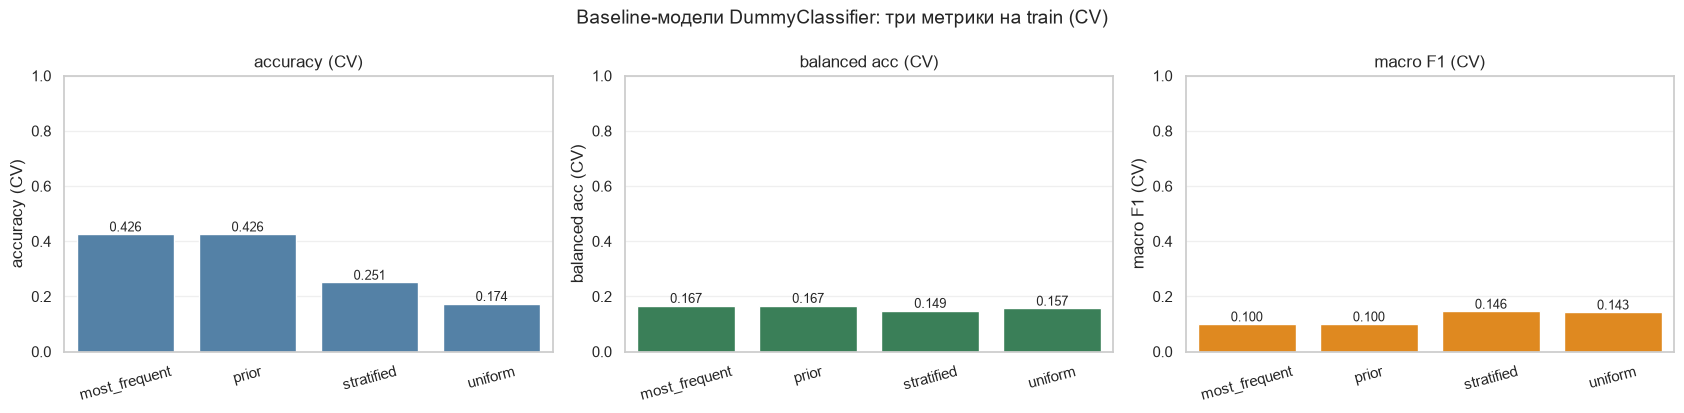

In [73]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))

metrics = ['accuracy (CV)', 'balanced acc (CV)', 'macro F1 (CV)']
colors = ['steelblue', 'seagreen', 'darkorange']

for ax, metric, color in zip(axes, metrics, colors):
    sns.barplot(data=dummy_table, x='стратегия', y=metric, color=color, ax=ax)
    ax.bar_label(ax.containers[0], fmt='%.3f', fontsize=9)
    ax.set_title(metric)
    ax.set_xlabel('')
    ax.set_ylim(0, 1.0)
    ax.tick_params(axis='x', rotation=15)
    ax.grid(alpha=0.3, axis='y')

plt.suptitle('Baseline-модели DummyClassifier: три метрики на train (CV)', fontsize=14)
plt.tight_layout()
plt.show()

**Сравнение baseline с настоящей моделью.** Сам по себе baseline ничего не значит — важно,
насколько его превосходит модель, которая действительно использует признаки. Обучим
логистическую регрессию на том же `X_train_scaled` и сопоставим метрики.

In [74]:
reference_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=5000),
)

reference_cv = cross_validate(
    reference_model, X_train_all[selected_columns], y_train_lr4,
    cv=cv_strategy,
    scoring=['accuracy', 'balanced_accuracy', 'f1_macro', 'f1_weighted'],
    n_jobs=-1,
)

reference_model.fit(X_train_all[selected_columns], y_train_lr4)
reference_prediction = reference_model.predict(X_test_all[selected_columns])

baseline_row = {
    'модель': 'LogisticRegression (отобранные признаки)',
    'accuracy (CV)': round(float(reference_cv['test_accuracy'].mean()), 3),
    'balanced acc (CV)': round(float(reference_cv['test_balanced_accuracy'].mean()), 3),
    'macro F1 (CV)': round(float(reference_cv['test_f1_macro'].mean()), 3),
    'weighted F1 (CV)': round(float(reference_cv['test_f1_weighted'].mean()), 3),
    'accuracy (test)': round(float(accuracy_score(y_test_lr4, reference_prediction)), 3),
    'macro F1 (test)': round(float(f1_score(y_test_lr4, reference_prediction, average='macro')), 3),
}

dummy_comparison = pd.concat(
    [
        dummy_table.assign(модель='DummyClassifier: ' + dummy_table['стратегия']),
        pd.DataFrame([baseline_row]),
    ],
    ignore_index=True,
)

dummy_comparison = dummy_comparison[
    ['модель', 'accuracy (CV)', 'balanced acc (CV)', 'macro F1 (CV)',
     'weighted F1 (CV)', 'accuracy (test)', 'macro F1 (test)']
]

dummy_comparison

,модель,accuracy (CV),balanced acc (CV),macro F1 (CV),weighted F1 (CV),accuracy (test),macro F1 (test)
0,DummyClassifier: most_frequent,0.426,0.167,0.100,0.254,0.426,0.100
1,DummyClassifier: prior,0.426,0.167,0.100,0.254,0.426,0.100
2,DummyClassifier: stratified,0.251,0.149,0.146,0.251,0.267,0.230
3,DummyClassifier: uniform,0.174,0.157,0.143,0.197,0.109,0.089
4,LogisticRegression (отобранные признаки),0.866,0.773,0.767,0.859,0.832,0.793


**Главный вывод по baseline.** `most_frequent` и `prior` дают одинаковые `accuracy` (0.426),
но `macro F1` всего **0.100**: модель угадывает самый частый класс и полностью проваливается
на остальных пяти. `stratified` и `uniform` выглядят «честнее» по `macro F1` (0.146 и 0.143),
но и они далеки от осмысленного уровня. Логистическая регрессия на отобранных признаках даёт
`macro F1` **0.767** на кросс-валидации и **0.793** на test — это и есть тот запас качества,
который создают признаки, а не угадывание.

**Зачем нужен именно такой baseline.** Он фиксирует две вещи: (1) любой результат ниже
`macro F1 ≈ 0.15` не лучше случайного угадывания; (2) высокий `accuracy` сам по себе ничего
не доказывает — при дисбалансе его легко получить, ничего не предсказывая.

In [75]:
print('Classification report логистической регрессии на test:')
print(classification_report(
    y_test_lr4, reference_prediction,
    digits=3, zero_division=0,
))

Classification report логистической регрессии на test:
               precision    recall  f1-score   support

 deep_barrier      0.500     0.600     0.545        10
inner_barrier      0.789     0.652     0.714        23
   inner_core      0.896     1.000     0.945        43
  inner_layer      0.923     0.750     0.828        16
  outer_layer      0.857     1.000     0.923         6
   rare_other      1.000     0.667     0.800         3

     accuracy                          0.832       101
    macro avg      0.828     0.778     0.793       101
 weighted avg      0.838     0.832     0.829       101



<a id='sec16-8'></a>
### 16.8. Проверки корректности и итоговые данные ЛР 4

**Проверки на утечку и согласованность.** Отдельно проверим главное: скалер и отбор
признаков обучены только на train, а test не участвовал ни в одном решении.

1. **Скалер обучен на train.** Средние по train после `transform` равны нулю с точностью
   до машинной погрешности, а `std` при `ddof=0` равна единице. В pandas `std()` по умолчанию
   считает `ddof=1`, поэтому там же выводится `1.002` — это не ошибка, а другая формула.
   Средние по test не равны нулю, значит, статистики test не пересчитывались.
2. **Размеры не изменились.** 235 объектов train и 101 test — как и после ЛР 3.
3. **Порядок строк сохранён.** Индексы `X` и `y` совпадают, поэтому метки не «переехали».
4. **Новых пропусков и бесконечностей нет.**
5. **Формулы не зависят от данных.** Проверим это напрямую: пересчитаем новые признаки
   на объединённой таблице и убедимся, что для строк train значения совпали.

In [76]:
recomputed = add_engineered_features(pd.concat([X_train_lr4, X_test_lr4]))
max_difference = float(
    (recomputed.loc[X_train_lr4.index] - X_train_new).abs().to_numpy().max()
)

checks_lr4 = {
    'скалер обучен на train: средние ≈ 0': bool(np.allclose(X_train_scaled.mean(axis=0), 0, atol=1e-9)),
    'скалер обучен на train: std ≈ 1': bool(
        np.allclose(X_train_scaled.to_numpy().std(axis=0, ddof=0), 1, atol=1e-9)
    ),
    'средние test не пересчитаны по test': not bool(np.allclose(X_test_scaled.mean(axis=0), 0, atol=1e-6)),
    'размер train не изменился': X_train_scaled.shape[0] == 235,
    'размер test не изменился': X_test_scaled.shape[0] == 101,
    'индексы X и y совпадают (train)': bool((X_train_scaled.index == y_train_lr4.index).all()),
    'индексы X и y совпадают (test)': bool((X_test_scaled.index == y_test_lr4.index).all()),
    'новых пропусков нет': int(X_train_all[selected_columns].isna().sum().sum()) == 0,
    'бесконечностей нет': int(np.isinf(X_train_all[selected_columns].to_numpy()).sum()) == 0,
    'формулы не зависят от набора строк': max_difference < 1e-12,
    'все 6 классов сохранены': y_train_lr4.nunique() == 6,
    'rare_other сохранён': int((y_train_lr4 == 'rare_other').sum()) == 6,
}

for check_name, check_result in checks_lr4.items():
    print(f'{"OK  " if check_result else "FAIL"} | {check_name}')

print()
print('Все проверки пройдены:', all(checks_lr4.values()))
print('Максимальное расхождение при пересчёте формул:', max_difference)

OK   | скалер обучен на train: средние ≈ 0
OK   | скалер обучен на train: std ≈ 1
OK   | средние test не пересчитаны по test
OK   | размер train не изменился
OK   | размер test не изменился
OK   | индексы X и y совпадают (train)
OK   | индексы X и y совпадают (test)
OK   | новых пропусков нет
OK   | бесконечностей нет
OK   | формулы не зависят от набора строк
OK   | все 6 классов сохранены
OK   | rare_other сохранён

Все проверки пройдены: True
Максимальное расхождение при пересчёте формул: 0.0


In [77]:
lr4_summary = pd.DataFrame([
    {'объект': 'X_train_scaled', 'форма': str(X_train_scaled.shape), 'пропуски': int(X_train_scaled.isna().sum().sum()),
     'комментарий': 'train, StandardScaler обучен на train'},
    {'объект': 'X_test_scaled', 'форма': str(X_test_scaled.shape), 'пропуски': int(X_test_scaled.isna().sum().sum()),
     'комментарий': 'test, применён transform'},
    {'объект': 'y_train_lr4', 'форма': str(y_train_lr4.shape), 'пропуски': 0,
     'комментарий': '6 классов, rare_other — 6'},
    {'объект': 'y_test_lr4', 'форма': str(y_test_lr4.shape), 'пропуски': 0,
     'комментарий': '6 классов'},
    {'объект': 'selected_columns', 'форма': str(len(selected_columns)), 'пропуски': 0,
     'комментарий': 'итоговый набор признаков'},
    {'объект': 'dummy_table', 'форма': str(dummy_table.shape), 'пропуски': int(dummy_table.isna().sum().sum()),
     'комментарий': 'baseline-метрики'},
])

lr4_summary

,объект,форма,пропуски,комментарий
0,X_train_scaled,"(235, 8)",0,"train, StandardScaler обучен на train"
1,X_test_scaled,"(101, 8)",0,"test, применён transform"
2,y_train_lr4,"(235,)",0,"6 классов, rare_other — 6"
3,y_test_lr4,"(101,)",0,6 классов
4,selected_columns,8,0,итоговый набор признаков
5,dummy_table,"(4, 7)",0,baseline-метрики


**Итоговое состояние данных ЛР 4.**

| Объект | Форма | Что содержит |
|---|---|---|
| `X_train_all` | 235 × 18 | исходные 6 + сгенерированные 12 признаков, без масштабирования |
| `X_test_all` | 101 × 18 | то же для test |
| `X_train_scaled` | 235 × k | отобранные признаки после `StandardScaler` |
| `X_test_scaled` | 101 × k | те же признаки, преобразованные обученным скалером |
| `selected_columns` | список | итоговый набор признаков, выбранный по CV на train |
| `dummy_table` | 4 × 7 | метрики четырёх baseline-стратегий |
| `dummy_comparison` | 5 × 7 | baseline + логистическая регрессия для сравнения |

Здесь `k` — число отобранных признаков (6 исходных плюс принятые новые).

### Выводы по ЛР 4

**Генерация признаков.**

1. Сформировано **12 новых признаков** тремя группами: баланс сил Radiant/Dire
   (`resonance_total`, `resonance_balance`, `radiant_share`), глубина проникновения
   (`energy_total`, `energy_balance`, `inner_share`) и взаимодействие силы с глубиной
   (`radiant_depth`, `dire_depth`, `depth_advantage`, `essence_energy`, `mark_energy`,
   `penetration_index`).
2. Все признаки — детерминированные формулы от исходных столбцов. Оцениваемых по данным
   величин в них нет, поэтому применение к test не создаёт утечки.
3. Отношения защищены константой `EPS = 1e-6`: пропусков и бесконечностей не возникло,
   несмотря на нулевые значения `radiant_resonance` и близкие к нулю суммы энергий.

**Диспропорция и масштабирование.**

1. **В исходных данных диспропорции практически нет:** все 6 признаков измеряются в долях
   0–1, отношение std составляет 1.79. Это важный вывод сам по себе — скалирование здесь
   нужно не из-за исходных данных.
2. **Диспропорция появляется после генерации.** На 18 объединённых признаках отношение std
   вырастает до **6.74**, а отношение размахов — до **10.4**: рядом с долями оказываются
   суммы (до 1.99) и отношения (до 5.48).
3. Сравнены четыре варианта на двух моделях. Масштабирование даёт заметный прирост
   `macro F1` у логистической регрессии (**0.657 → 0.744**) и у kNN (**0.614 → 0.717**).
   Это подтверждает, что диспропорция реальна и её нужно устранять.
4. Выбран **`StandardScaler`**: он даёт лучший или близкий к лучшему результат на обеих
   моделях, устойчив к несимметричным распределениям новых признаков и не привязан
   к экстремумам, как `MinMaxScaler`.
5. **`RobustScaler` оказался хуже из-за нулевого IQR у `arcane_mark` и `mark_energy`:**
   sklearn оставляет для них масштаб `1.0`, и бинарный флаг начинает доминировать
   в расстоянии. Это конкретная проверенная причина, а не общее рассуждение
   о «чувствительности к выбросам».

**Отбор признаков.**

1. Обнаружено **7 пар** с корреляцией выше 0.9 — в основном дубликаты по построению
   (`energy_total` с `outer_energy_flow` и `inner_energy_flow` — r = 0.945 и 0.944;
   `mark_energy` с `arcane_mark` — r = 0.952).
2. Последовательный отбор по кросс-валидации оставил только **два** новых признака:
   `radiant_depth` и `dire_depth`. Итоговый набор из **8 признаков** даёт `macro F1`
   **0.767** против **0.761** у исходных 6.
3. **Все 18 признаков дают 0.744** — хуже, чем исходные 6. Это ключевой результат:
   генерация признаков полезна не «количеством», а только теми, кто несёт новую информацию.
   Механическое добавление всех признаков ухудшает модель из-за коррелированных дубликатов.

**Baseline-модели.**

1. Обучены четыре `DummyClassifier`. `most_frequent` и `prior` дают `accuracy` **0.426**,
   но `macro F1` всего **0.100** — они предсказывают только `inner_core`.
2. `stratified` и `uniform` дают `macro F1` **0.146** и **0.143** — это уровень случайного
   угадывания с учётом дисбаланса.
3. Логистическая регрессия на отобранных признаках даёт `macro F1` **0.767** на CV
   и **0.793** на test, то есть **в 5 раз выше** лучшего dummy-варианта.
4. **Вывод о метрике:** при дисбалансе классов ориентироваться на `accuracy` нельзя.
   `most_frequent` показывает 42.6% «точности», не предсказав ни одного объекта
   из пяти классов. Основная метрика для этой задачи — `macro F1` и `balanced accuracy`.

**Ограничения.**

- **Отбор признаков выполнен на логистической регрессии.** Деревья и бустинг могут
  выбрать другие признаки, поэтому в ЛР 5 отбор стоит перепроверить на финальных моделях.
- **`rare_other` содержит 6 объектов.** Любая метрика по этому классу определяется
  несколькими наблюдениями, поэтому `macro F1` имеет заметный разброс (std ≈ 0.086).
- **Порог прироста `0.0005` выбран вручную.** При другом пороге число отобранных признаков
  изменится.
- **Формулы признаков — гипотеза о предметной области.** Они опираются на смысл «глубина
  и направление проникновения», но не проверены на внешних данных.

**Что используется в ЛР 5.** `X_train_scaled`, `y_train_lr4`, `X_test_scaled`, `y_test_lr4`
(отобранные признаки после `StandardScaler`) и `dummy_table` как эталон качества.